# Introduction

Welcome to this project. In this notebook, we will develop a machine learning pipeline to detect
and classify malicious network traffic. We are utilizing the CICIDS2017 dataset, a highly
regarded benchmark in cybersecurity that contains realistic background traffic combined with 
modern attack profiles.

## 1. The Objective of the Project

The primary goal of this project is to build a robust, data-driven Network Intrusion Detection System (NIDS) capable of analyzing network flow features to distinguish between benign traffic and cyber threats.
Specifically, the project aims to:

* Develop an automated model that identifies malicious activity (e.g., DoS, DDoS, PortScan, Brute Force, Web Attacks) from high-dimensional network flow data.

* Construct an efficient and scalable data preprocessing pipeline capable of handling the massive scale of the CICIDS2017 dataset, handling anomalies like infinite or missing values gracefully.

* Reduce the reliance on traditional signature-based detection systems by leveraging machine learning to identify complex and potentially novel attack patterns based on behavioral features.

## 2. Framing the Problem

We frame this task as a Supervised Machine Learning problem, as we have access to labeled instances of both benign and malicious network flows.

*   Task Type: This is a Classification task. We can approach it on two levels:

    * Binary Classification: A simplified model to predict whether a network flow is Benign (1) or an Attack (0).
    * Multiclass Classification: A more granular model to predict the specific type of traffic (e.g., Benign, DoS Hulk, FTP-Patator, etc.) for targeted threat response.


*   Learning Paradigm: We will be using Batch (Offline) Learning. The model will be trained comprehensively on the 
    static dataset rather than learning incrementally on a live stream, though the resulting model could theoretically be deployed for real-time inference.

## 3. Performance Measures

Network traffic data is inherently highly imbalanced; benign traffic vastly outnumbers malicious traffic. Consequently, relying strictly on Accuracy is dangerously misleading (a model that predicts everything as benign might achieve 90%+ accuracy but is useless for security).

To properly evaluate our models, we will use the following metrics:

*   Recall (Sensitivity): The proportion of actual attacks that the model correctly identified. In a security context, maximizing recall is critical to minimize False Negatives (threats slipping through the network undetected).

*   Precision: The proportion of predicted attacks that were genuinely malicious. High precision minimizes False Positives, which is essential to prevent "alert fatigue" for Security Operations Center (SOC) analysts.

*   F1-Score: The harmonic mean of Precision and Recall. This will serve as our primary single-number metric, as it forces the model to balance the trade-off between missing attacks and generating false alarms.

*   Confusion Matrix: To visually diagnose which specific classes (attack types) the model is confusing with one another.


# Imports and Configuration

In [146]:
import numpy as np
import pandas as pd
import polars as pl
import polars.selectors as cs
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.base import TransformerMixin, BaseEstimator
from sklearn.utils.validation import check_array, check_is_fitted
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')



pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(-1)

polars.config.Config

# Loading the dataset and merging dataframes

The latest version of cicids2017 is divided into five files containing various data which need to be merged into one file

In [147]:
files = Path("../data/raw").glob("*.csv")
dfs = []

for file in files:
    df = pl.read_csv(file)
    df = df.rename({c: c.strip() for c in df.columns})
    dfs.append(df)

data = pl.concat(dfs)

# Data Ingestion: Downcast Types & Save to Parquet

The cicids2017 dataset is a large dataset with +2M rows so we'll convert it from csv to parquet for better memory management

In [148]:
data.write_parquet("../data/processed/cicids2017.parquet")
data = pl.read_parquet("../data/processed/cicids2017.parquet")

Downcastin the numerical data to 32 bit

In [149]:
data = data.with_columns(pl.col(pl.Float64()).cast(pl.Float32()))
data = data.with_columns(pl.col(pl.Int64()).cast(pl.Int32()))

In [5]:
df = data.clone()

# 1. Initial Data Exploration

## 1.1 Data overview

### 1.1.1 Data dimensions

In [125]:
data.shape

(2100814, 84)

### 1.1.2 First few rows

In [126]:
data.head(10)

Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
str,str,i32,str,i32,i32,str,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,f32,str
"""192.168.10.50-192.168.10.3-561…","""192.168.10.50""",56108,"""192.168.10.3""",3268,6,"""07/07/2017 01:59:50 PM""",112740690,32,16,6448.0,1152.0,403.0,0.0,201.5,204.724197,72.0,72.0,72.0,0.0,67.411331,0.425756,2.398738e6,5.798698e6,1.6399772e7,3.0,1.12740688e8,3636796.5,6.848761e6,1.6399772e7,3.0,1.12740352e8,7.516023e6,8.323385e6,1.640011e7,3.0,16,16,0,0,1024,512,0.283837,0.141919,0.0,403.0,158.333328,177.341751,31450.099609,0,0,0,32,48,0,0,0,0.5,158.333328,201.5,72.0,0,0,0,0,0,0,0,134,0,24,377,2079,15,32,359.428558,11.998015,380.0,343.0,1.6105402e7,498804.8125,1.6399772e7,1.5375229e7,"""BENIGN"""
"""192.168.10.50-192.168.10.3-421…","""192.168.10.50""",42144,"""192.168.10.3""",389,6,"""07/07/2017 01:59:50 PM""",112740560,32,16,6448.0,5056.0,403.0,0.0,201.5,204.724197,316.0,316.0,316.0,0.0,102.039589,0.425756,2.3987e6,5798709.5,1.6399782e7,2.0,1.1274056e8,3.6368e6,6.848777e6,1.6399782e7,2.0,1.1274024e8,7.516016e6,8.323376e6,1.640011e7,4.0,16,16,0,0,1024,512,0.283837,0.141919,0.0,403.0,239.666672,174.984177,30619.460938,0,0,0,32,48,0,0,0,0.5,239.666672,201.5,316.0,0,0,0,0,0,0,0,134,0,105,955,2079,15,32,320.285706,15.744991,330.0,285.0,1.6105427e7,498793.65625,1.6399782e7,1.5375263e7,"""BENIGN"""
"""8.6.0.1-8.0.6.4-0-0-0""","""8.6.0.1""",0,"""8.0.6.4""",0,0,"""07/07/2017 02:00:31 PM""",113757377,545,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.790898,209112.828125,1.3955e6,2.075703e7,0.0,1.13757376e8,209112.828125,1.3955e6,2.075703e7,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,4.790898,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,9.361829e6,7.324646e6,1.8851792e7,19.0,1.2210358e7,6.935824e6,2.075703e7,5.504997e6,"""BENIGN"""
"""192.168.10.25-224.0.0.251-5353…","""192.168.10.25""",5353,"""224.0.0.251""",5353,17,"""07/07/2017 02:00:42 PM""",91997219,388,0,37151.0,0.0,227.0,37.0,95.75,55.78532,0.0,0.0,0.0,0.0,403.827423,4.217519,237718.90625,1.5116e6,1.9776792e7,0.0,9.1997216e7,237718.90625,1.5116e6,1.9776792e7,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,3104,0,4.217519,0.0,37.0,227.0,95.75,55.78532,3112.001953,0,0,0,0,0,0,0,0,0.0,95.75,95.75,0.0,1857,19,9453,0,0,0,1,95,0,0,0,0,387,8,9.801664e6,1.1527818e7,2.4721964e7,16.0,1.3197637e7,5826904.5,1.9776792e7,5.81747e6,"""BENIGN"""
"""192.168.10.25-17.253.14.125-12…","""192.168.10.25""",123,"""17.253.14.125""",123,17,"""07/07/2017 02:00:42 PM""",6

### 1.1.3 Data types 

In [127]:
data.to_pandas().info()

<class 'pandas.DataFrame'>
RangeIndex: 2100814 entries, 0 to 2100813
Data columns (total 84 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Flow ID                     str    
 1   Src IP                      str    
 2   Src Port                    int32  
 3   Dst IP                      str    
 4   Dst Port                    int32  
 5   Protocol                    int32  
 6   Timestamp                   str    
 7   Flow Duration               int32  
 8   Total Fwd Packet            int32  
 9   Total Bwd packets           int32  
 10  Total Length of Fwd Packet  float32
 11  Total Length of Bwd Packet  float32
 12  Fwd Packet Length Max       float32
 13  Fwd Packet Length Min       float32
 14  Fwd Packet Length Mean      float32
 15  Fwd Packet Length Std       float32
 16  Bwd Packet Length Max       float32
 17  Bwd Packet Length Min       float32
 18  Bwd Packet Length Mean      float32
 19  Bwd Packet Length Std       floa

In [128]:
data.dtypes

[String,
 String,
 Int32,
 String,
 Int32,
 Int32,
 String,
 Int32,
 Int32,
 Int32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Float32,
 Float32,
 Float32,
 Float32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 String]

In [129]:
data["Label"].unique()

Label
str
"""DoS Hulk - Attempted"""
"""DoS Slowhttptest - Attempted"""
"""Web Attack - Brute Force - Att…"
"""PortScan"""
"""Web Attack - Brute Force"""
"""Bot"""
"""Web Attack - XSS - Attempted"""
"""DoS Hulk"""
"""Bot - Attempted"""


### 1.1.4 CICIDS2017 Feature Dictionary


The dataset contains 84 features extracted from network traffic flows. In network terminology, **Forward (Fwd)** refers to traffic from the source to the destination, and **Backward (Bwd)** refers to traffic from the destination back to the source.

#### 1. Flow Identifiers (Often dropped during ML preprocessing)
*   **Flow ID:** A unique string identifying the connection (Source IP, Dest IP, Ports, Protocol).
*   **Source IP:** The IP address of the machine initiating the flow.
*   **Source Port:** The port number used by the initiator.
*   **Destination IP:** The IP address of the receiving machine.
*   **Destination Port:** The port number of the receiving machine.
*   **Protocol:** The transport layer protocol used (e.g., 6 for TCP, 17 for UDP).
*   **Timestamp:** The exact time the flow started.

#### 2. Core Flow Metrics
*   **Flow Duration:** Total time the flow lasted (in microseconds).
*   **Total Fwd Packets:** Number of packets sent in the forward direction.
*   **Total Backward Packets:** Number of packets sent in the backward direction.
*   **Total Length of Fwd Packets:** Total size of all forward packets (in bytes).
*   **Total Length of Bwd Packets:** Total size of all backward packets (in bytes).
*   **Flow Bytes/s:** Throughput of the flow in bytes per second.
*   **Flow Packets/s:** Packet transmission rate of the flow per second.
*   **Fwd Packets/s:** Rate of forward packets per second.
*   **Bwd Packets/s:** Rate of backward packets per second.

#### 3. Packet Length Statistics
*   **Fwd Packet Length Max:** Largest forward packet size.
*   **Fwd Packet Length Min:** Smallest forward packet size.
*   **Fwd Packet Length Mean:** Average forward packet size.
*   **Fwd Packet Length Std:** Standard deviation of forward packet sizes.
*   **Bwd Packet Length Max:** Largest backward packet size.
*   **Bwd Packet Length Min:** Smallest backward packet size.
*   **Bwd Packet Length Mean:** Average backward packet size.
*   **Bwd Packet Length Std:** Standard deviation of backward packet sizes.
*   **Min Packet Length:** Smallest packet size across the entire flow.
*   **Max Packet Length:** Largest packet size across the entire flow.
*   **Packet Length Mean:** Average packet size across the entire flow.
*   **Packet Length Std:** Standard deviation of all packet sizes.
*   **Packet Length Variance:** Variance of all packet sizes.
*   **Average Packet Size:** Mean packet size (similar to Packet Length Mean but calculated differently in CICFlowMeter).
*   **Avg Fwd Segment Size:** Average size of a forward TCP segment.
*   **Avg Bwd Segment Size:** Average size of a backward TCP segment.
*   **Fwd Header Length:** Total bytes used for forward headers. *(Note: Sometimes appears twice in raw data due to a legacy tool bug).*
*   **Bwd Header Length:** Total bytes used for backward headers.
*   **min_seg_size_forward:** Minimum segment size observed in the forward direction.

#### 4. Inter-Arrival Time (IAT) Statistics
*IAT measures the time delay between two consecutive packets.*
*   **Flow IAT Mean:** Average time between any two packets.
*   **Flow IAT Std:** Standard deviation of the flow IAT.
*   **Flow IAT Max:** Longest delay between any two packets.
*   **Flow IAT Min:** Shortest delay between any two packets.
*   **Fwd IAT Total:** Total time spent waiting between forward packets.
*   **Fwd IAT Mean:** Average delay between forward packets.
*   **Fwd IAT Std:** Standard deviation of forward IAT.
*   **Fwd IAT Max:** Longest delay between forward packets.
*   **Fwd IAT Min:** Shortest delay between forward packets.
*   **Bwd IAT Total:** Total time spent waiting between backward packets.
*   **Bwd IAT Mean:** Average delay between backward packets.
*   **Bwd IAT Std:** Standard deviation of backward IAT.
*   **Bwd IAT Max:** Longest delay between backward packets.
*   **Bwd IAT Min:** Shortest delay between backward packets.

#### 5. TCP Flag Counts
*   **Fwd PSH Flags:** Number of times the PSH (Push) flag was set in forward packets.
*   **Bwd PSH Flags:** Number of times the PSH flag was set in backward packets.
*   **Fwd URG Flags:** Number of times the URG (Urgent) flag was set in forward packets.
*   **Bwd URG Flags:** Number of times the URG flag was set in backward packets.
*   **FIN Flag Count:** Total packets with the FIN (Finish) flag.
*   **SYN Flag Count:** Total packets with the SYN (Synchronize) flag.
*   **RST Flag Count:** Total packets with the RST (Reset) flag.
*   **PSH Flag Count:** Total packets with the PSH flag.
*   **ACK Flag Count:** Total packets with the ACK (Acknowledgment) flag.
*   **URG Flag Count:** Total packets with the URG flag.
*   **CWE Flag Count:** Total packets with the CWE (Congestion Window Reduced) flag.
*   **ECE Flag Count:** Total packets with the ECE (ECN-Echo) flag.

#### 6. Subflow and Bulk Rate Metrics
*   **Down/Up Ratio:** Ratio of download (backward) to upload (forward) traffic.
*   **Subflow Fwd Packets:** Number of forward packets in a subflow (usually matches Total Fwd Packets).
*   **Subflow Fwd Bytes:** Bytes sent forward in a subflow.
*   **Subflow Bwd Packets:** Number of backward packets in a subflow.
*   **Subflow Bwd Bytes:** Bytes sent backward in a subflow.
*   **Fwd Avg Bytes/Bulk:** Average forward bytes per bulk operation.
*   **Fwd Avg Packets/Bulk:** Average forward packets per bulk operation.
*   **Fwd Avg Bulk Rate:** Average forward bulk transfer rate.
*   **Bwd Avg Bytes/Bulk:** Average backward bytes per bulk operation.
*   **Bwd Avg Packets/Bulk:** Average backward packets per bulk operation.
*   **Bwd Avg Bulk Rate:** Average backward bulk transfer rate.

#### 7. Window Size and State Metrics
*   **Init_Win_bytes_forward:** Total number of bytes sent in initial window in the forward direction.
*   **Init_Win_bytes_backward:** Total number of bytes sent in initial window in the backward direction.
*   **act_data_pkt_fwd:** Count of packets carrying actual data (payload) in the forward direction.
*   **Active Mean:** Average time a flow was active before going idle.
*   **Active Std:** Standard deviation of active time.
*   **Active Max:** Longest time a flow was active before going idle.
*   **Active Min:** Shortest time a flow was active before going idle.
*   **Idle Mean:** Average time a flow was idle before becoming active again.
*   **Idle Std:** Standard deviation of idle time.
*   **Idle Max:** Longest time a flow was idle.
*   **Idle Min:** Shortest time a flow was idle.

#### 8. Target Label
*   **Label:** The target class (e.g., `Benign`, `Attempted`, or specific attack types like `DoS Hulk`).

*Explaining class labels*


*   `BENIGN`                                            Normal traffic
*   `DDoS`                                              Distributed Denial of Service
*   `DoS Hulk`                                          DoS attack using Hulk
*   `DoS GoldenEye`                                     GoldenEye Dos
*   `DoS slowloris`                                     Slowloris DoS
*   `DoS Slowhttptest`                                  Slow HTTP attack
*   `PortScan`                                          Port scanning/reconnaissance
*   `FTP-Patator`                                       FTP brute-force
*   `SSH-Patator`                                       SSH brute-force
*   `Web Attack – Brute Force`                          Web login/password brute force
*   `Web Attack – XSS`                                  Cross-site scripting
*   `Web Attack – SQL Injection`                        SQL injection
*   `Infiltration`                                      Network infiltration
*   `Bot`                                               Botnet traffic
*   `Heartbleed`                                        Heartbleed exploitation           

*"Attempted" vs. Actual Attack Flows*
*   Attempted Flows (The Bycatch): These are network flows that originated during an attack sequence but do not contain the actual attack payload. They typically fall into three categories:
    *    Startup/Teardown Artifacts (TCP Appendices): The initial TCP handshake (SYN/ACK) to establish the connection, or the connection closure (FIN/RST), without any data transfer.
    *    No Malicious Payload: Auxiliary connections made by the attacker's machine, such as downloading a background file, pinging a server, or flows that are completely empty.
    *    Failed Implementations: Attack scripts that fired incorrectly and failed to execute the intended exploit.

*   Actual Attack Flows: These are the self-contained, successfully executed network flows that carry the active malicious payload (e.g., the actual SQL injection string, the flood of packets for a DoS, or the repeated login attempts for a Brute Force).

*Handling Attempted flows*
It's recommended to label attempted flows as Benign which we'll do

## 1.2 Duplicates

In [95]:
# polars.DataFrame.is_duplicated Marks all instances of a duplicate as True unlike pandas.DataFrame.duplicated() which marks the first
# occurrence 
data.is_duplicated().sum()

6286

We got 3143 duplicates but other duplicates might appear after dropping identifier features

## 1.3 Missing and infinite Values

In [ ]:

total_rows = data.height


nulls = data.select(pl.all().is_null().sum()).unpivot(
    variable_name="Feature", value_name="Missing_Count"
)


infs = data.select(cs.numeric().is_infinite().sum()).unpivot(
    variable_name="Feature", value_name="Inf_Count"
)


nans = data.select(cs.numeric().is_nan().sum()).unpivot(
    variable_name="Feature", value_name="NaN_Count"
)


summary = (
    nulls
    .join(infs, on="Feature", how="left")
    .join(nans, on="Feature", how="left")
    .fill_null(0)
)


summary = summary.with_columns(
    (pl.col("Missing_Count") / total_rows * 100).round(4).alias("Missing_%"),
    (pl.col("Inf_Count") / total_rows * 100).round(4).alias("Inf_%"),
    (pl.col("NaN_Count") / total_rows * 100).round(4).alias("NaN_%")
)


issues_only = summary.filter(
    (pl.col("Missing_Count") > 0) | 
    (pl.col("Inf_Count") > 0) | 
    (pl.col("NaN_Count") > 0)
)

print(issues_only)

shape: (6, 7)
┌────────────────┬───────────────┬───────────┬───────────┬───────────┬────────┬────────┐
│ Feature        ┆ Missing_Count ┆ Inf_Count ┆ NaN_Count ┆ Missing_% ┆ Inf_%  ┆ NaN_%  │
│ ---            ┆ ---           ┆ ---       ┆ ---       ┆ ---       ┆ ---    ┆ ---    │
│ str            ┆ u32           ┆ u32       ┆ u32       ┆ f64       ┆ f64    ┆ f64    │
╞════════════════╪═══════════════╪═══════════╪═══════════╪═══════════╪════════╪════════╡
│ Flow Bytes/s   ┆ 0             ┆ 191       ┆ 602       ┆ 0.0       ┆ 0.0091 ┆ 0.0287 │
│ Flow Packets/s ┆ 0             ┆ 793       ┆ 0         ┆ 0.0       ┆ 0.0377 ┆ 0.0    │
│ Flow IAT Mean  ┆ 0             ┆ 0         ┆ 252       ┆ 0.0       ┆ 0.0    ┆ 0.012  │
│ Flow IAT Std   ┆ 0             ┆ 0         ┆ 252       ┆ 0.0       ┆ 0.0    ┆ 0.012  │
│ Flow IAT Max   ┆ 0             ┆ 0         ┆ 252       ┆ 0.0       ┆ 0.0    ┆ 0.012  │
│ Flow IAT Min   ┆ 0             ┆ 0         ┆ 252       ┆ 0.0       ┆ 0.0    ┆ 0.012  │
└──────

The missing and infinite values numbers are so small soo we'll consider dropping them if they don't severly affect label classes

## 1.4 Outliers

In [97]:
numeric_cols = data.select(cs.numeric()).columns


stats = data.select(
    [pl.col(c).quantile(0.25).alias(f"{c}_q1") for c in numeric_cols] +
    [pl.col(c).quantile(0.75).alias(f"{c}_q3") for c in numeric_cols]
).to_dicts()[0]


outlier_exprs = []
for c in numeric_cols:
    q1 = stats[f"{c}_q1"]
    q3 = stats[f"{c}_q3"]
    
    
    if q1 is not None and q3 is not None:
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        
        
        expr = (
            (pl.col(c) < lower_bound) | (pl.col(c) > upper_bound)
        ).sum().alias(c)
        outlier_exprs.append(expr)


outliers_summary = (
    data.select(outlier_exprs)
    .unpivot(variable_name="Feature", value_name="Outlier_Count")
    .filter(pl.col("Outlier_Count") > 0)
    .sort("Outlier_Count", descending=True)
)

print(outliers_summary.head(20))

shape: (20, 2)
┌────────────────────────────┬───────────────┐
│ Feature                    ┆ Outlier_Count │
│ ---                        ┆ ---           │
│ str                        ┆ u32           │
╞════════════════════════════╪═══════════════╡
│ Idle Mean                  ┆ 467087        │
│ Idle Max                   ┆ 467087        │
│ Idle Min                   ┆ 467087        │
│ Bwd IAT Std                ┆ 466727        │
│ Bwd IAT Total              ┆ 466436        │
│ Bwd IAT Mean               ┆ 462501        │
│ Bwd IAT Max                ┆ 460773        │
│ Active Mean                ┆ 460221        │
│ Active Max                 ┆ 460221        │
│ Active Min                 ┆ 460221        │
│ Fwd IAT Std                ┆ 456757        │
│ Flow Bytes/s               ┆ 435374        │
│ Fwd PSH Flags              ┆ 409996        │
│ Total Length of Bwd Packet ┆ 355733        │
│ Fwd IAT Mean               ┆ 354919        │
│ Flow IAT Mean              ┆ 353351        

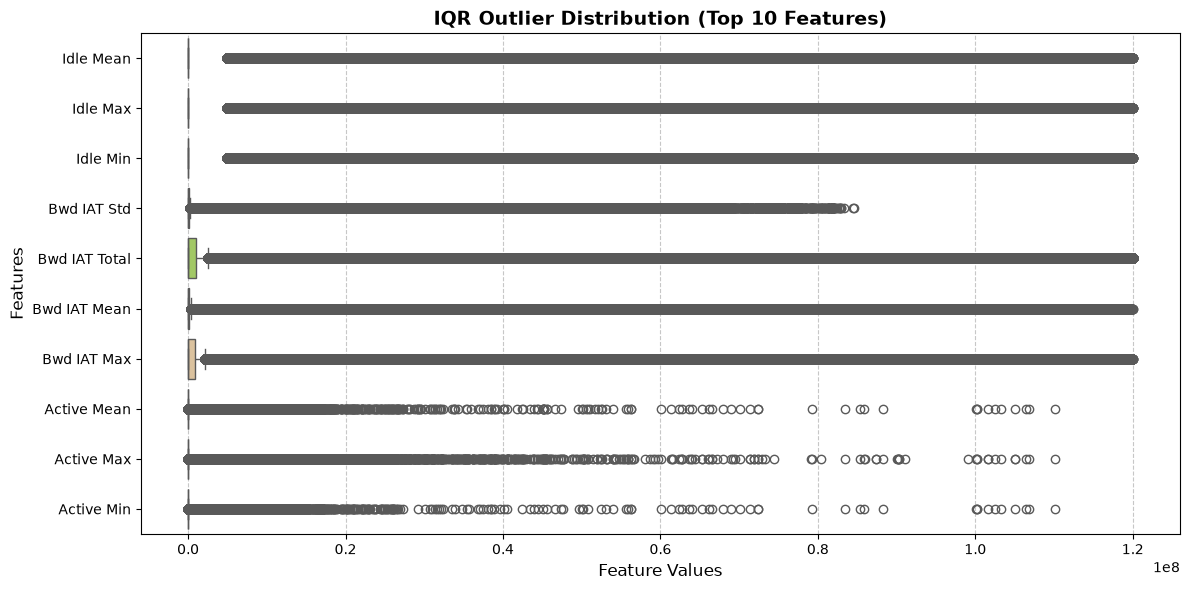

In [13]:
top_features = outliers_summary.head(10)["Feature"].to_list()


plot_data = data.select(top_features).to_pandas()


plt.figure(figsize=(12, 6))
sns.boxplot(data=plot_data, orient="h", palette="Set2")

plt.title("IQR Outlier Distribution (Top 10 Features)", fontsize=14, fontweight='bold')
plt.xlabel("Feature Values", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()



In [14]:
numeric_cols = data.select(cs.numeric().exclude("Src Port", "Dst Port")).columns


n_cols = 2
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 6 * n_rows))
axes = axes.flatten()
data_copy = data.clone()
data_copy = data_copy.with_columns(
    pl.when(cs.numeric().is_infinite())
    .then(None)
    .otherwise(cs.numeric())
    .name.keep()
)
data_copy = data_copy.with_columns(
    cs.float().fill_nan(None).name.keep()
)
data_copy = data_copy.drop_nulls()

for i, col_name in enumerate(numeric_cols):
    ax = axes[i]
    
    col_array = data_copy[col_name].to_numpy()
    
    
    if len(col_array) == 0:
        continue
        
    
    counts, breakpoints = np.histogram(col_array, bins=50)

    sort_indices = np.argsort(counts)[::-1]
    sorted_counts = counts[sort_indices]

    bin_starts = breakpoints[:-1]
        
    sorted_bin_starts = bin_starts[sort_indices]

    x_positions = np.arange(len(sorted_counts))
    

    ax.bar(
        x_positions, 
        sorted_counts, 
        color='#1b4965', 
        edgecolor='black', 
        linewidth=0.3,
        alpha=0.85
    )
    

    ax.set_yscale('log')
    ax.set_ylim(bottom=0.5)
    
    ax.set_title(col_name, fontsize=8, fontweight='bold')
    ax.set_xticks(x_positions)
    

    formatted_labels = [f"{val:.2g}" for val in sorted_bin_starts]
    ax.set_xticklabels(formatted_labels, rotation=90, fontsize=10)

    ax.tick_params(axis='y', which='major', labelsize=6)
    ax.grid(True, axis='y', linestyle=':', alpha=0.3)


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()

### Outlier Analysis: Why We Keep Extreme Values

Upon analyzing the IQR results, several features appear to contain a massive number of outliers. However, visualizing the distributions via histograms and boxplots reveals that the data is heavily **zero-inflated** (the vast majority of values are exactly zero). Because the 25th and 75th percentiles are often both zero, the IQR mathematically flags *any* non-zero value as an outlier.

In the context of cybersecurity, we must handle extreme values differently than in standard datasets:
* **Outliers are Signatures:** A sudden, extreme spike in values (e.g., 500,000 packets per second) is often the exact mathematical signature of an active threat, such as a Denial of Service (DoS) attack.
* **Preserving the Signal:** Deleting these outliers would inadvertently delete the malicious behavior our NIDS is trying to learn. 

**Preprocessing Strategy:** 
We will not clip or drop outliers. Instead, we will preserve the integrity of the attack signatures by utilizing **tree-based models** (like Random Forest), which make split decisions and are inherently immune to extreme scale differences. And if we used distance based models, we will use a **RobustScaler** to handle the scale variance without distorting the extreme values.

## 1.5 Impossible Negatives

In [98]:
negatives_summary = (
    data.select((cs.numeric() < 0).sum())
    .unpivot(variable_name="Feature", value_name="Negative_Count")
    .filter(pl.col("Negative_Count") > 0)
    .sort("Negative_Count", descending=True)
)

print(negatives_summary)

shape: (5, 2)
┌────────────────┬────────────────┐
│ Feature        ┆ Negative_Count │
│ ---            ┆ ---            │
│ str            ┆ u32            │
╞════════════════╪════════════════╡
│ Flow IAT Min   ┆ 2922           │
│ Flow Duration  ┆ 31             │
│ Flow Packets/s ┆ 31             │
│ Flow IAT Mean  ┆ 31             │
│ Flow IAT Max   ┆ 31             │
└────────────────┴────────────────┘


Due to known timestamp parsing anomalies and packet synchronization bugs in the network capture tools used to generate the CICIDS2017 dataset, certain flow features occasionally record impossible negative values. 

Since time increments, packet lengths, and flow sizes cannot physically be negative, these instances represent corrupted extraction artifacts rather than genuine network behavior or attack signatures. To maintain the mathematical integrity of the training data, we will identify the affected features and drop the corrupted rows entirely.

## 1.6 Non-Zero Count

In [38]:
non_zero_summary = (
    data.select((cs.numeric() != 0).sum())
    .unpivot(variable_name="Feature", value_name="Non_Zero_Count")
    .sort("Non_Zero_Count", descending=False)
)

print(non_zero_summary)

shape: (79, 2)
┌────────────────────────────┬────────────────┐
│ Feature                    ┆ Non_Zero_Count │
│ ---                        ┆ ---            │
│ str                        ┆ u32            │
╞════════════════════════════╪════════════════╡
│ Bwd URG Flags              ┆ 1              │
│ Fwd URG Flags              ┆ 93             │
│ URG Flag Count             ┆ 94             │
│ Subflow Bwd Packets        ┆ 161            │
│ ECE Flag Count             ┆ 686            │
│ CWR Flag Count             ┆ 764            │
│ Subflow Fwd Packets        ┆ 55266          │
│ Fwd Bytes/Bulk Avg         ┆ 86987          │
│ Fwd Packet/Bulk Avg        ┆ 86987          │
│ Fwd Bulk Rate Avg          ┆ 86987          │
│ Active Std                 ┆ 215095         │
│ Idle Std                   ┆ 220299         │
│ Bwd Bytes/Bulk Avg         ┆ 291646         │
│ Bwd Packet/Bulk Avg        ┆ 291646         │
│ Bwd Bulk Rate Avg          ┆ 291646         │
│ Active Mean            

In [42]:
low_non_zero_features = list(non_zero_summary[:4,0])
low_non_zero_features

['Bwd URG Flags', 'Fwd URG Flags', 'URG Flag Count', 'Subflow Bwd Packets']

We Notice some features the have a very low non-zero count and we'll consider dropping them in the cleaning

## 1.7 Traffic and Attack Exploration

In [150]:
base_label = pl.col("Label").str.replace(r" - Attempted$", "")

eda_df = (
    data
    .filter(pl.all_horizontal(cs.float().is_finite()))   
    .filter(~pl.any_horizontal(cs.numeric() < 0))        
    .with_columns(
        pl.col("Timestamp").str.strptime(pl.Datetime, "%d/%m/%Y %I:%M:%S %p"),
        pl.when(pl.col("Label") == "BENIGN").then(pl.lit("Benign"))
          .when(pl.col("Label").str.ends_with("Attempted")).then(pl.lit("Attempted"))
          .otherwise(pl.lit("Attack"))
          .alias("Category"),
        pl.when(base_label == "BENIGN").then(pl.lit("Benign"))
          .when(base_label.str.starts_with("DoS")).then(pl.lit("DoS"))
          .when(base_label.str.contains("Patator")).then(pl.lit("Brute Force"))
          .when(base_label.str.starts_with("Web Attack")).then(pl.lit("Web Attack"))
          .otherwise(base_label)
          .alias("Family"),
    )
    .with_columns(pl.col("Timestamp").dt.strftime("%A").alias("Day"))
)

DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
FAMILY_ORDER = ["DoS", "DDoS", "PortScan", "Brute Force", "Web Attack", "Bot", "Infiltration", "Heartbleed"]
tab10 = sns.color_palette("tab10", 10).as_hex()
FAMILY_COLORS = dict(zip(["Benign"] + FAMILY_ORDER, ["#9aa5b1"] + [tab10[i] for i in (0, 1, 2, 3, 4, 5, 6, 8)]))

attacks = eda_df.filter(pl.col("Category") == "Attack")

eda_df.group_by("Category", "Family").len().sort("Category", "len", descending=[False, True])

Category,Family,len
str,str,u32
"""Attack""","""DoS""",171586
"""Attack""","""PortScan""",159023
"""Attack""","""DDoS""",95098
"""Attack""","""Brute Force""",6947
"""Attack""","""Bot""",738
"""Attack""","""Web Attack""",190
"""Attack""","""Infiltration""",31
"""Attack""","""Heartbleed""",7
"""Attempted""","""DoS""",5732


### 1.7.1 Are "Attempted" flows really harmless?
By definition, an "Attempted" flow belongs to an attack that needs a payload to work, but the flow itself carries no payload. If that is true, these flows should have **zero forward payload bytes** (`Total Length of Fwd Packet == 0`).

We compare Attempted and real attack flows inside each family that has Attempted labels (PortScan and DDoS have none, since they do not rely on a payload). The dashed line is the level for benign traffic.

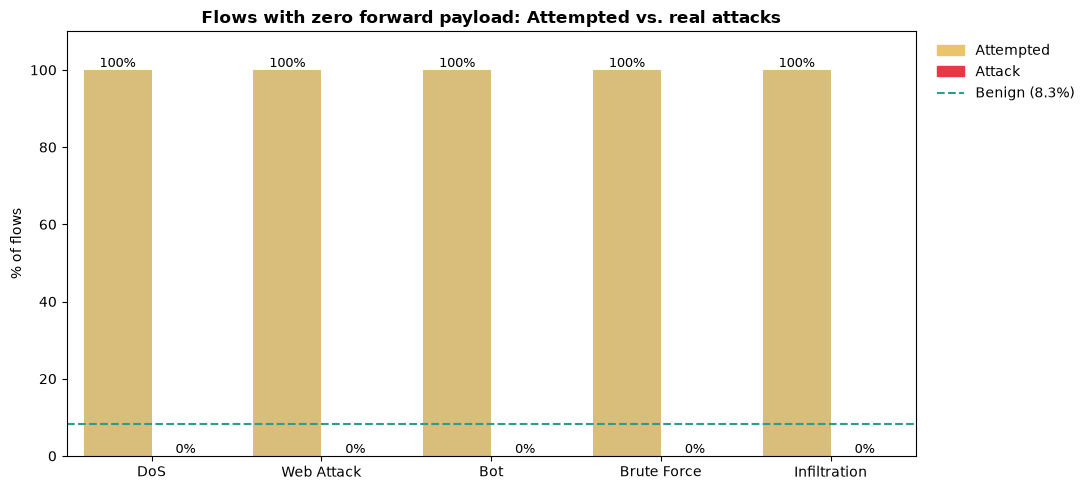

In [151]:
payload_families = ["DoS", "Web Attack", "Bot", "Brute Force", "Infiltration"]
zero_payload = (pl.col("Total Length of Fwd Packet") == 0).mean() * 100

payload = (
    eda_df.filter(pl.col("Family").is_in(payload_families))
    .group_by("Family", "Category")
    .agg(zero_payload.alias("Zero payload %"))
    .to_pandas()
)
benign_zero = eda_df.filter(pl.col("Category") == "Benign").select(zero_payload).item()

plt.figure(figsize=(11, 5))
ax = sns.barplot(data=payload, x="Family", y="Zero payload %", hue="Category",
                 order=payload_families, hue_order=["Attempted", "Attack"],
                 palette={"Attempted": "#e9c46a", "Attack": "#e63946"})
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", fontsize=9)
ax.axhline(benign_zero, color="#2a9d8f", linestyle="--", linewidth=1.5)
ax.legend(handles=[Patch(color="#e9c46a", label="Attempted"), Patch(color="#e63946", label="Attack"),
                   Line2D([0], [0], color="#2a9d8f", linestyle="--", label=f"Benign ({benign_zero:.1f}%)")],
          frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.title("Flows with zero forward payload: Attempted vs. real attacks", fontweight="bold")
plt.ylabel("% of flows")
plt.xlabel("")
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

**Observations**
* In every family that has Attempted labels, **100%** of Attempted flows carry no forward payload, while **0%** of the real attack flows do. For comparison, 8.3% of benign flows have no payload.
* The split is perfect: the "Attempted" label is exactly the set of attack-session flows that never delivered a payload (connection set-up/tear-down, empty connections).
* Without a payload these flows cannot have any effect, and their features look like an ordinary empty TCP connection. This supports our decision to **relabel Attempted flows as BENIGN** (section 2.5): keeping them as attacks would teach the model to flag harmless empty connections.

### 1.7.2 Attacks per day
CICIDS2017 was captured over five working days, and each day hosts different attack scenarios.

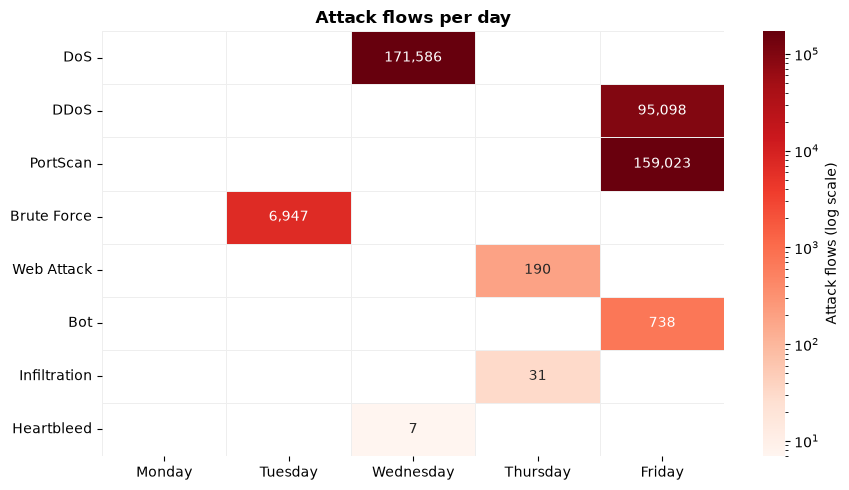

In [152]:
per_day = (
    attacks.group_by("Family", "Day").len()
    .pivot(on="Day", index="Family", values="len")
    .fill_null(0)
    .to_pandas()
    .set_index("Family")
    .reindex(index=FAMILY_ORDER, columns=DAY_ORDER, fill_value=0)
)

plt.figure(figsize=(9, 5))
sns.heatmap(per_day, annot=True, fmt=",", cmap="Reds", norm=LogNorm(),
            mask=per_day == 0, linewidths=0.5, linecolor="#eeeeee",
            cbar_kws={"label": "Attack flows (log scale)"})
plt.title("Attack flows per day", fontweight="bold")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Observations**
* **Monday contains only benign traffic.** It is the baseline day.
* Each attack family appears on **exactly one day**: Brute Force on Tuesday; DoS and Heartbleed on Wednesday; Web Attack and Infiltration on Thursday; Bot, PortScan and DDoS on Friday.
* The classes are extremely unbalanced. DoS (171,586 flows) and PortScan (159,023) dominate, while Infiltration has 31 flows and Heartbleed only 7.
* The PortScan count shrinks to about 1,670 after de-duplication in section 2.2. Scan probes are identical once IPs and ports are removed, so 99% of them are duplicates.

### 1.7.3 Which services does each attack target?
The destination port tells us which service an attack is aimed at. For each family we show the share of its flows going to its top 3 destination ports, and how many different ports it touches.

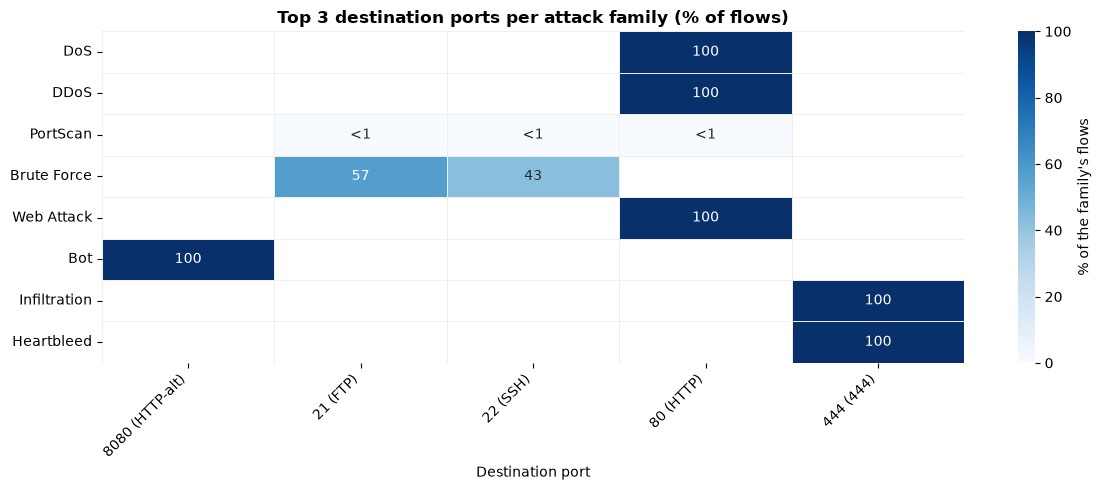

Family,Distinct destination ports
str,u32
"""PortScan""",1001
"""Brute Force""",2
"""Infiltration""",1
"""Bot""",1
"""DDoS""",1
"""DoS""",1
"""Heartbleed""",1
"""Web Attack""",1


In [ ]:
SERVICES = {21: "FTP", 22: "SSH", 53: "DNS", 80: "HTTP", 123: "NTP", 137: "NetBIOS", 139: "NetBIOS",
            443: "HTTPS", 444: "SNPP", 445: "SMB", 8080: "HTTP-alt"}

port_share = (
    attacks.group_by("Family", "Dst Port").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("Family") * 100).alias("Share %"))
    .sort(["Family", "len"], descending=[False, True])
    .group_by("Family", maintain_order=True).head(3)
    .with_columns(
        pl.col("Dst Port").map_elements(lambda p: f"{p} ({SERVICES[p]})" if p in SERVICES else str(p),
                                        return_dtype=pl.String).alias("Port")
    )
)

port_matrix = (
    port_share.pivot(on="Port", index="Family", values="Share %")
    .fill_null(0).to_pandas().set_index("Family").reindex(FAMILY_ORDER)
)

plt.figure(figsize=(12, 5))
port_labels = port_matrix.map(lambda v: "" if v == 0 else ("<1" if v < 1 else f"{v:.0f}"))
sns.heatmap(port_matrix, annot=port_labels, fmt="", cmap="Blues", mask=port_matrix == 0, vmin=0, vmax=100,
            linewidths=0.5, linecolor="#eeeeee", cbar_kws={"label": "% of the family's flows"})
plt.title("Top 3 destination ports per attack family (% of flows)", fontweight="bold")
plt.xlabel("Destination port")
plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

attacks.group_by("Family").agg(pl.col("Dst Port").n_unique().alias("Distinct destination ports")).sort("Distinct destination ports", descending=True)

**Observations**
* Every family except PortScan targets **one single service**:
  * DoS, DDoS and Web Attack all hit the web server on port **80 (HTTP)**.
  * Brute Force splits between **FTP (21, 57%)** and **SSH (22, 43%)**. These are the FTP-Patator and SSH-Patator tools.
  * Bot talks to its command-and-control server on **8080**.
  * Infiltration and Heartbleed both use port **444**.
* PortScan is the opposite. Its flows are spread over **1,001 different ports**, and no single port receives even 1% of them.
* `Dst Port` would therefore be a very strong but **misleading** feature. The model would learn "port 444 means attack" from this particular lab set-up instead of learning attack behaviour. This is why it is dropped together with the other identifiers in section 2.1.

### 1.7.4 Transport protocol per family
Share of TCP, UDP and other flows within benign traffic and each attack family.

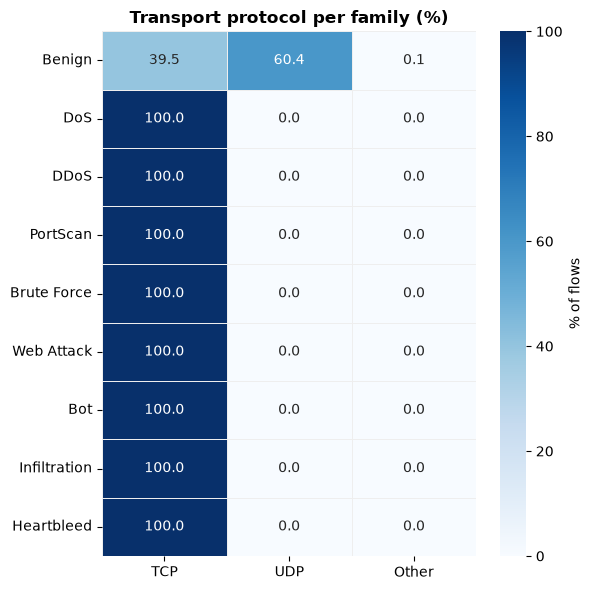

In [155]:
protocol_matrix = (
    eda_df.filter(pl.col("Category") != "Attempted")
    .with_columns(
        pl.col("Protocol").replace_strict({6: "TCP", 17: "UDP"}, default="Other", return_dtype=pl.String)
        .alias("Transport")
    )
    .group_by("Family", "Transport").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("Family") * 100).alias("Share %"))
    .pivot(on="Transport", index="Family", values="Share %")
    .fill_null(0)
    .to_pandas()
    .set_index("Family")
    .reindex(index=["Benign"] + FAMILY_ORDER, columns=["TCP", "UDP", "Other"], fill_value=0)
)

plt.figure(figsize=(6, 6))
sns.heatmap(protocol_matrix, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            linewidths=0.5, linecolor="#eeeeee", cbar_kws={"label": "% of flows"})
plt.title("Transport protocol per family (%)", fontweight="bold")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Observations**
* **All attack flows use TCP (100%)**, while 60% of benign flows are UDP.
* In this dataset, any UDP flow is therefore benign, and `Protocol` alone already separates a large part of the benign traffic.
* This is a property of this lab, not of attacks in general (UDP floods, DNS amplification and similar attacks exist). We should be careful that the model does not depend on it too much.

### 1.7.5 When do attacks happen

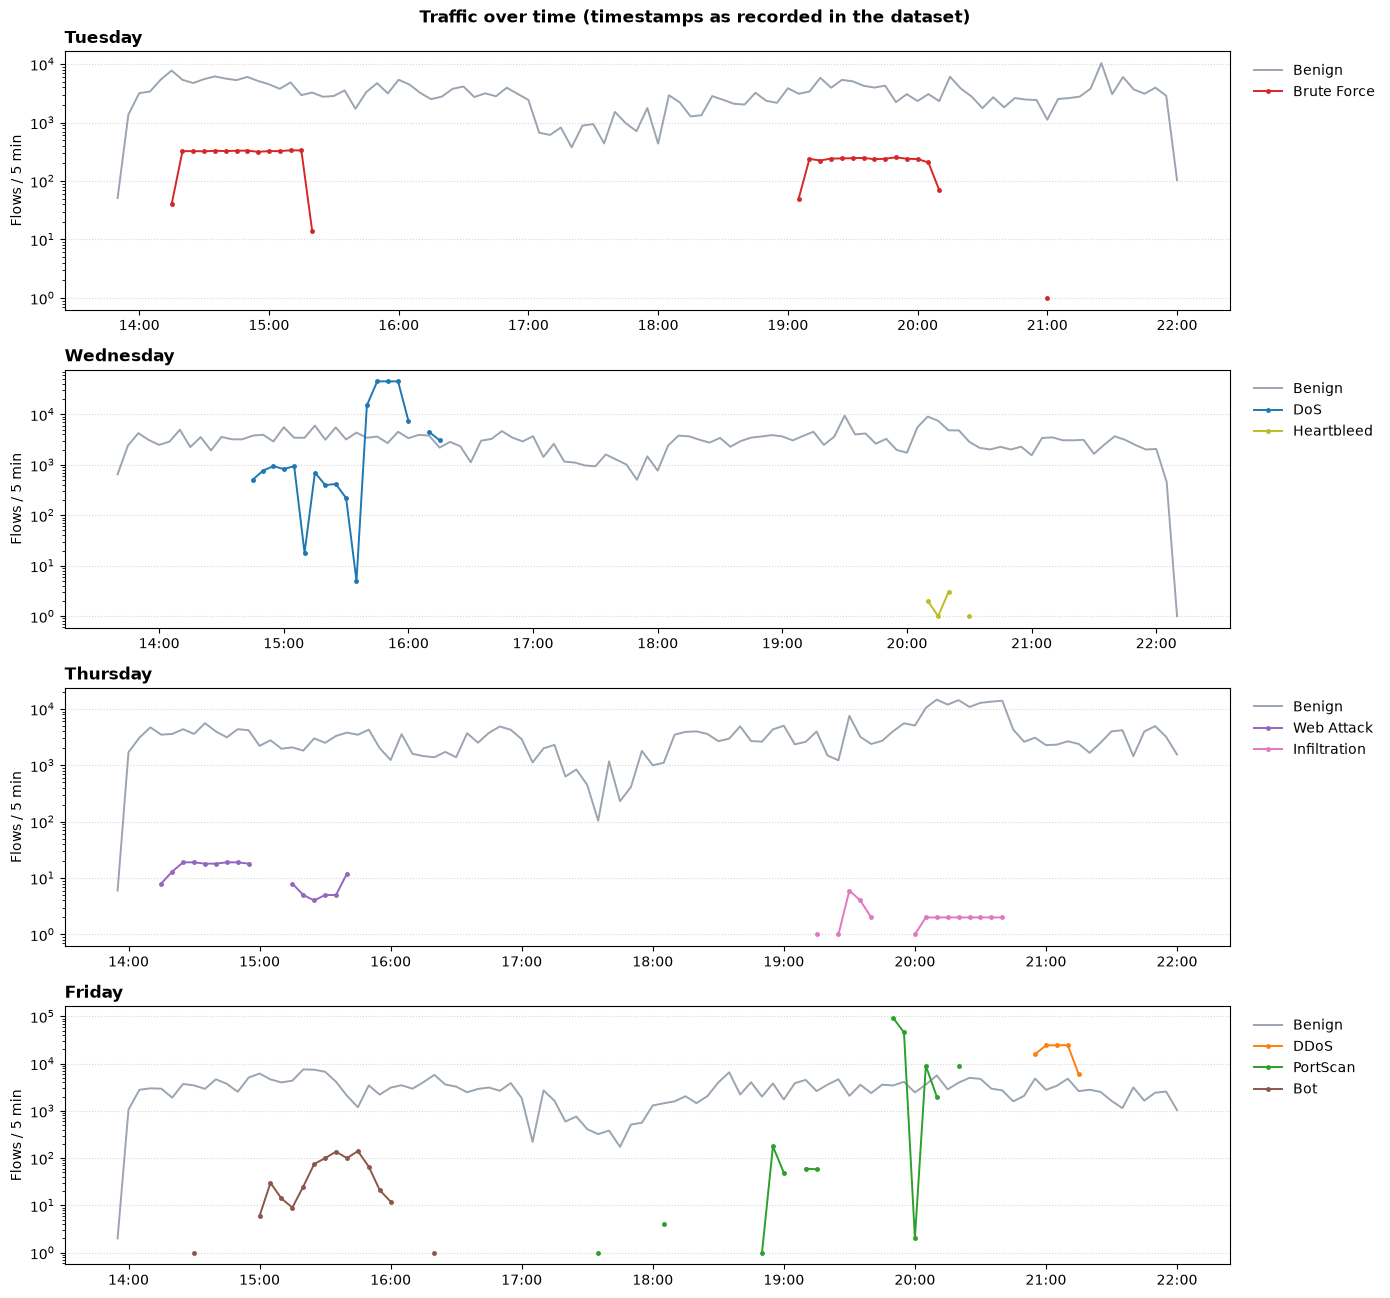

In [ ]:
attack_days = ["Tuesday", "Wednesday", "Thursday", "Friday"]

timeline = (
    eda_df.filter(pl.col("Day").is_in(attack_days) & (pl.col("Category") != "Attempted"))
    .with_columns(pl.col("Timestamp").dt.truncate("5m").alias("Time"))
    .group_by("Day", "Time", "Family").len()
    .sort("Time")
    .to_pandas()
)

fig, axes = plt.subplots(len(attack_days), 1, figsize=(14, 3.3 * len(attack_days)))
for ax, day in zip(axes, attack_days):

    day_data = (timeline[timeline["Day"] == day]
                .pivot(index="Time", columns="Family", values="len")
                .asfreq("5min"))
    for family in ["Benign"] + FAMILY_ORDER:
        if family in day_data:
            ax.plot(day_data.index, day_data[family], label=family, color=FAMILY_COLORS[family],
                    linewidth=1.4, marker=None if family == "Benign" else "o", markersize=2.5)
    ax.set_yscale("log")
    ax.set_title(day, fontweight="bold", loc="left")
    ax.set_xlabel("")
    ax.set_ylabel("Flows / 5 min")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    ax.grid(axis="y", linestyle=":", alpha=0.5)

plt.suptitle("Traffic over time (timestamps as recorded in the dataset)", fontweight="bold")
plt.tight_layout()
plt.show()

**Observations**
* The recorded timestamps run from about 14:00 to 22:00. That is **5 hours ahead** of the lab's local working day: the official schedule lists FTP-Patator at 9:20 and DDoS at 15:56, which appear here at 14:17 and 20:56.
* Attacks are **short bursts** on top of a steady benign background of about 10³–10⁴ flows per 5 minutes:
  * Brute Force runs in two one-hour blocks (FTP, then SSH).
  * The DoS tools run one after another, and DoS Hulk peaks above 4×10⁴ flows per 5 minutes.
  * PortScan and DDoS reach 10⁴–10⁵ flows per 5 minutes, which is more than all benign traffic at that moment.
* Low-volume attacks (Web Attack, Infiltration, Heartbleed, Bot) stay far below the benign level. They cannot be spotted by traffic volume, only by the behaviour of each individual flow, which is what our flow-based model learns.

### 1.7.6 Benign vs. attack: key feature distributions
Distributions of selected features for benign and attack flows, on a `log10(1 + x)` scale because most features are heavily skewed. We use a random sample of 100,000 flows per class, and each class is normalised separately so their shapes can be compared.

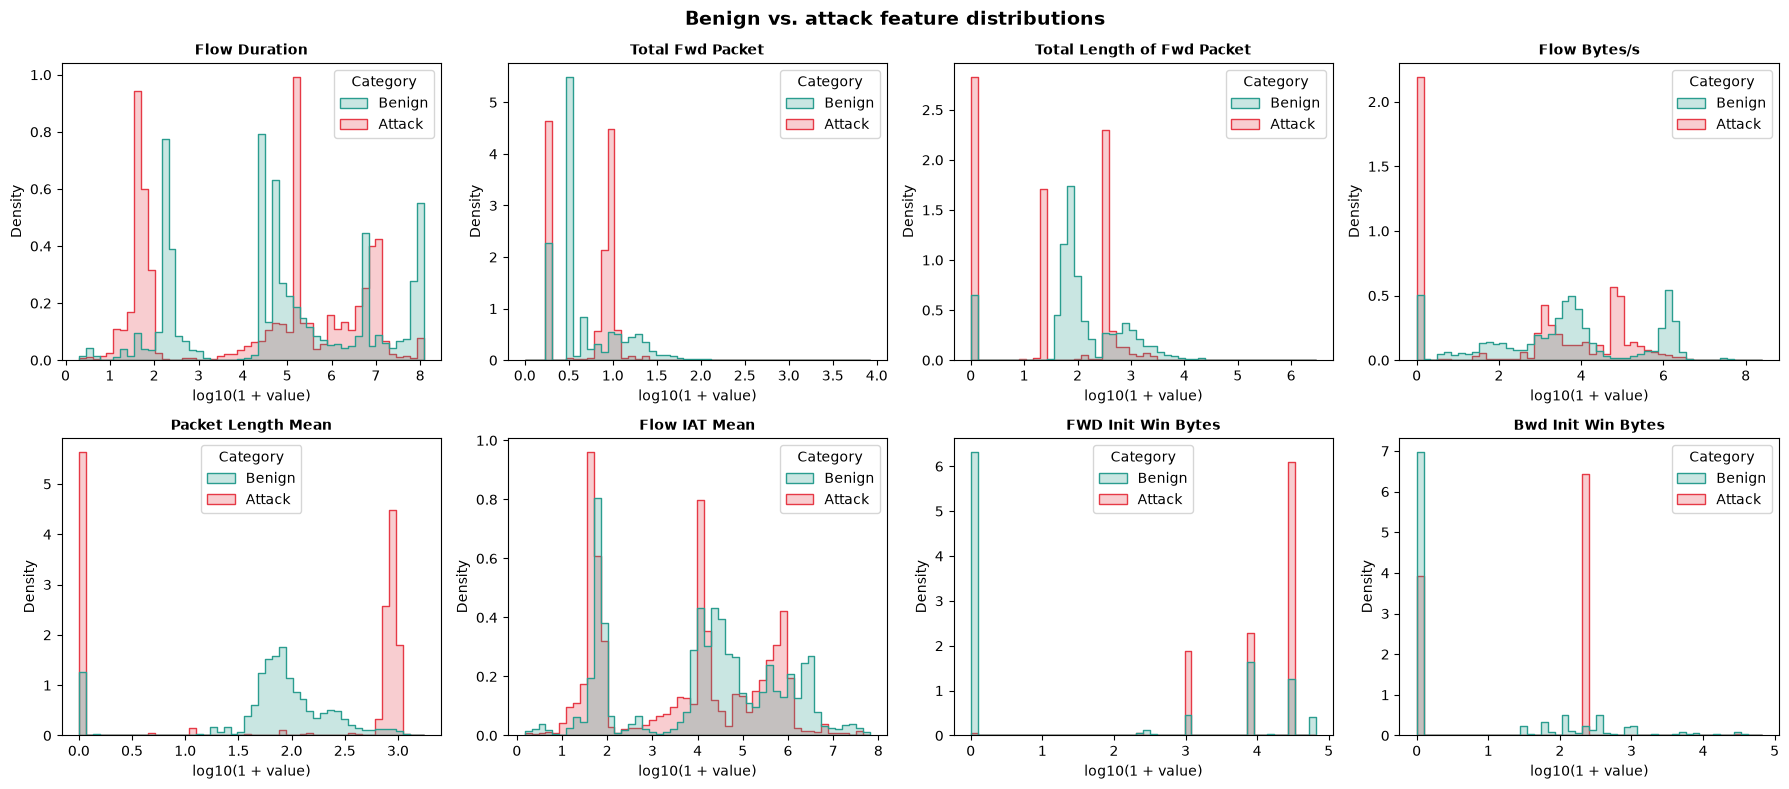

In [156]:
dist_features = ["Flow Duration", "Total Fwd Packet", "Total Length of Fwd Packet", "Flow Bytes/s",
                 "Packet Length Mean", "Flow IAT Mean", "FWD Init Win Bytes", "Bwd Init Win Bytes"]

dist_sample = (
    eda_df.filter(pl.col("Category") != "Attempted")
    .filter(pl.int_range(pl.len()).shuffle(seed=42).over("Category") < 100_000)
    .select(["Category"] + [(pl.col(c).cast(pl.Float64) + 1).log10().alias(c) for c in dist_features])
    .to_pandas()
)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feature in zip(axes.flatten(), dist_features):
    sns.histplot(data=dist_sample, x=feature, hue="Category", hue_order=["Benign", "Attack"],
                 palette={"Benign": "#2a9d8f", "Attack": "#e63946"}, stat="density",
                 common_norm=False, element="step", bins=50, ax=ax)
    ax.set_title(feature, fontweight="bold", fontsize=10)
    ax.set_xlabel("log10(1 + value)")
plt.suptitle("Benign vs. attack feature distributions", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

**Observations**
* Attack flows concentrate on a few **sharp peaks**, while benign flows are spread out. Attacks are generated by tools that repeat the same request over and over. For example, `Packet Length Mean` for attacks peaks at 0 (PortScan probes with no payload) and at about 1,000 bytes (DoS/DDoS HTTP responses).
* `FWD Init Win Bytes` and `Bwd Init Win Bytes` take only a few fixed values for attacks: the initial TCP window sizes of the attacker and victim machines' operating systems. They are very predictive here, but partly describe the lab machines rather than the attack itself (a possible shortcut).
* Several features overlap strongly between the two classes (`Flow IAT Mean`, `Flow Duration`). No single feature separates benign from attack, so the model has to combine many features.

### 1.7.7 Attack fingerprints
Median value of key features for each family. The numbers in the cells are the real medians; the colours are scaled per column (on a log scale), so each column shows which families are high or low for that feature.

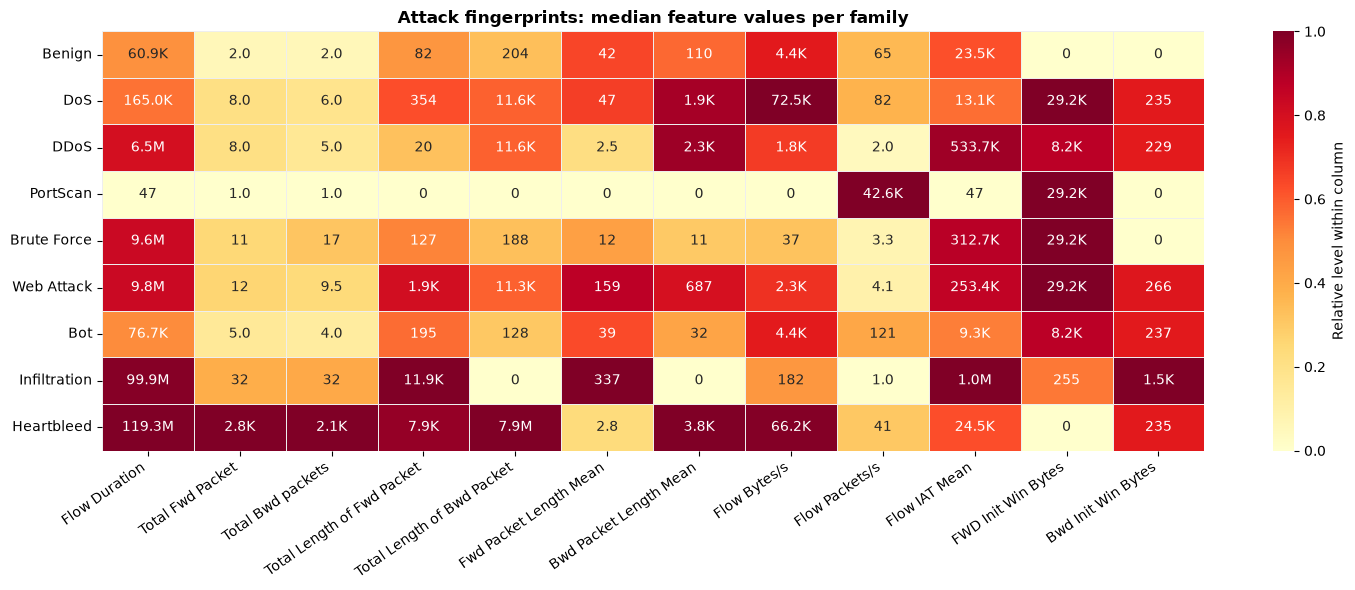

In [157]:
fingerprint_features = ["Flow Duration", "Total Fwd Packet", "Total Bwd packets",
                        "Total Length of Fwd Packet", "Total Length of Bwd Packet",
                        "Fwd Packet Length Mean", "Bwd Packet Length Mean",
                        "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean",
                        "FWD Init Win Bytes", "Bwd Init Win Bytes"]

medians = (
    eda_df.filter(pl.col("Category") != "Attempted")
    .group_by("Family")
    .agg([pl.col(c).median() for c in fingerprint_features])
    .to_pandas()
    .set_index("Family")
    .reindex(["Benign"] + FAMILY_ORDER)
)

log_medians = np.log10(1 + medians)
colour_scale = (log_medians - log_medians.min()) / (log_medians.max() - log_medians.min()).replace(0, 1)

def short_number(v):
    for limit, suffix in ((1e9, "B"), (1e6, "M"), (1e3, "K")):
        if abs(v) >= limit:
            return f"{v / limit:.1f}{suffix}"
    return f"{v:.0f}" if v >= 10 or v == 0 else f"{v:.1f}"

plt.figure(figsize=(15, 6))
sns.heatmap(colour_scale, annot=medians.map(short_number), fmt="", cmap="YlOrRd",
            linewidths=0.5, linecolor="#eeeeee", cbar_kws={"label": "Relative level within column"})
plt.title("Attack fingerprints: median feature values per family", fontweight="bold")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Observations:** each family has a clearly different profile.
* **PortScan:** 1 packet in each direction, zero payload, 47 µs duration. Tiny probes.
* **DoS / DDoS:** short-to-medium flows with a large backward volume (median 11.6 KB from the server). The attacked web server is answering the flood of requests.
* **Brute Force and Web Attack:** long (about 10 s) but slow flows (3–4 packets/s) with small payloads. These are repeated login or form submissions.
* **Infiltration and Heartbleed:** very long flows, 100–120 s. That is the 120-second flow timeout of CICFlowMeter, so these are long-lived connections cut into 2-minute pieces. Heartbleed moves a median of 7.9 MB from the server per flow: the leaked server memory.
* **Bot:** values close to benign traffic. This makes Bot one of the harder families to detect.
* Several attack families share `FWD Init Win Bytes` = 29,200 (the attacker machine), while the benign median is 0. This confirms the shortcut risk noted above.

### 1.7.8 TCP flag behaviour
Percentage of flows in each family that contain at least one packet with the given TCP flag. Flags describe how a connection is opened (SYN), used (PSH, ACK) and closed (FIN, RST).

In [ ]:
flag_cols = ["SYN Flag Count", "ACK Flag Count", "PSH Flag Count", "FIN Flag Count",
             "RST Flag Count", "URG Flag Count", "CWR Flag Count", "ECE Flag Count"]

flag_matrix = (
    eda_df.filter(pl.col("Category") != "Attempted")
    .group_by("Family")
    .agg([((pl.col(c) > 0).mean() * 100).alias(c.replace(" Flag Count", "")) for c in flag_cols])
    .to_pandas()
    .set_index("Family")
    .reindex(["Benign"] + FAMILY_ORDER)
)

plt.figure(figsize=(9, 6))
sns.heatmap(flag_matrix, annot=True, fmt=".0f", cmap="PuBu", vmin=0, vmax=100,
            linewidths=0.5, linecolor="#eeeeee", cbar_kws={"label": "% of flows with the flag"})
plt.title("TCP flags per family (% of flows)", fontweight="bold")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Observations**
* Only about a third of benign flows contain TCP flags, because 60% of benign traffic is UDP.
* **PortScan:** SYN, ACK and RST in 100% of flows, but never PSH or FIN. This is the classic signature of a SYN scan: open a connection, receive a reset, never send data.
* **DoS / DDoS:** almost every flow contains RST (96–100%). The connections are torn down abruptly.
* **Brute Force, Web Attack and Bot:** connections are opened (SYN), used (PSH) and closed cleanly (FIN).
* **Infiltration and Heartbleed:** only 10–16% of flows contain SYN or FIN. Most of their flows are continuations of long connections split by the flow timeout (see 1.6.7).
* **URG, CWR and ECE are never used by any family.** They carry no information and can be dropped.

### 1.6.9 How separable are the classes? (PCA)
We project the flow features onto two principal components to see whether the families form separate groups. Features are `log10(1 + x)` transformed and standardised first. We sample up to 3,000 flows per family so that small families stay visible.

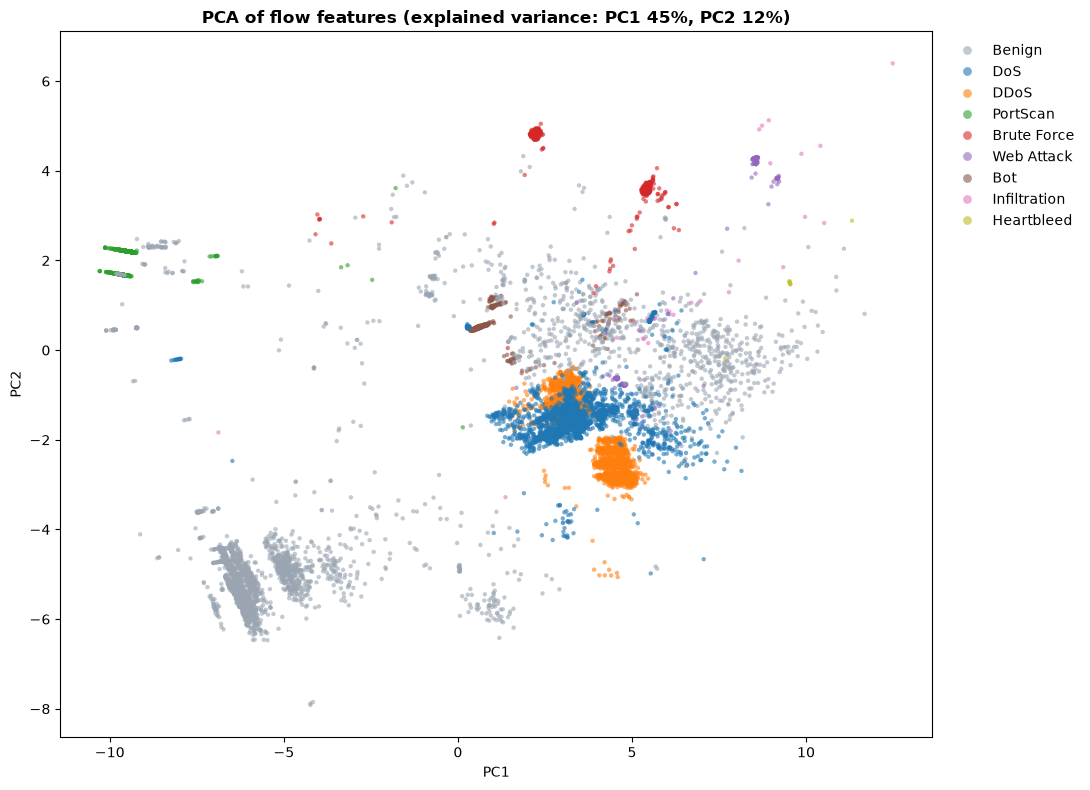

In [158]:
id_cols = ["Src Port", "Dst Port", "Protocol"]
pca_features = [c for c in eda_df.select(cs.numeric()).columns if c not in id_cols]

pca_sample = (
    eda_df.filter(pl.col("Category") != "Attempted")
    .filter(pl.int_range(pl.len()).shuffle(seed=42).over("Family") < 3_000)
)

X_pca = np.log10(1 + pca_sample.select(pca_features).to_numpy().astype(np.float64))
X_pca = StandardScaler().fit_transform(X_pca)

pca = PCA(n_components=2, random_state=42)
components = pca.fit_transform(X_pca)

pca_plot = pd.DataFrame(components, columns=["PC1", "PC2"])
pca_plot["Family"] = pca_sample["Family"].to_list()

plt.figure(figsize=(11, 8))
sns.scatterplot(data=pca_plot, x="PC1", y="PC2", hue="Family", hue_order=["Benign"] + FAMILY_ORDER,
                palette=FAMILY_COLORS, s=10, alpha=0.6, linewidth=0)
plt.title(f"PCA of flow features (explained variance: "
          f"PC1 {pca.explained_variance_ratio_[0]:.0%}, PC2 {pca.explained_variance_ratio_[1]:.0%})",
          fontweight="bold")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, markerscale=2)
plt.tight_layout()
plt.show()

**Observations**
* The first two components explain 57% of the variance.
* Benign flows spread over the whole space, while each attack family forms **one or a few tight clusters**. Tool-generated traffic is very regular.
* Brute Force forms two compact clusters (FTP and SSH), and PortScan sits in its own region on the far left.
* DoS and DDoS overlap with each other, and partly with benign traffic.
* Even this simple linear 2-D projection separates most families. This explains why tree-based models reach near-perfect scores on this dataset.
* The hard cases are the small families that sit inside the benign cloud: Bot, Web Attack and Infiltration.

### 1.7.10 Summary of the exploration
1. **Attempted flows never carry a payload** (100% vs. 0% for real attacks), which justifies relabelling them as BENIGN.
2. **Every attack comes from one tool, on one day, against one service.** Identifiers such as `Dst Port`, `Timestamp` and the IPs would let the model memorise the lab set-up, so dropping them (section 2.1) is necessary.
3. **All attacks are TCP**, while most benign traffic is UDP. TCP flags give clear signatures (for example SYN + RST without data for PortScan). URG, CWR and ECE are never used.
4. **Attack traffic is highly repetitive.** It forms tight clusters, and PortScan is 99% duplicates. After de-duplication some classes become tiny (Heartbleed 7, Web Attack – SQL Injection 12 flows), so per-class evaluation must be read with care, and grouping into families helps.
5. **Attacks are easy to separate from benign traffic overall**, but the low-volume families that look like normal traffic (Bot, Web Attack, Infiltration) are the real challenge for the model.
6. **Watch for shortcut features.** The initial TCP window sizes (`FWD Init Win Bytes`, `Bwd Init Win Bytes`) partly reflect the lab machines. Their feature importance should be checked after training.

# 2. Data Cleaning

## 2.1 Identifier Columns

In [130]:
data = data.drop(['Flow ID','Src IP','Src Port','Dst IP','Dst Port','Timestamp'])

In [131]:
data.shape

(2100814, 78)

In [132]:
data.is_duplicated().sum()

450353

## 2.2 Handling Attempted Rows

In [133]:
data["Label"].unique()

Label
str
"""Web Attack - Sql Injection"""
"""Infiltration - Attempted"""
"""SSH-Patator - Attempted"""
"""Web Attack - XSS"""
"""Infiltration"""
"""PortScan"""
"""DoS GoldenEye - Attempted"""
"""Heartbleed"""
"""Web Attack - Brute Force - Att…"


In [134]:
data = data.with_columns(
    pl.when(pl.col("Label").str.ends_with("Attempted"))
    .then(pl.lit("BENIGN"))
    .otherwise(pl.col("Label"))
    .alias("Label")
)

In [135]:
data["Label"].unique()

Label
str
"""Web Attack - Brute Force"""
"""DDoS"""
"""DoS Hulk"""
"""Web Attack - XSS"""
"""Heartbleed"""
"""Bot"""
"""PortScan"""
"""Infiltration"""
"""DoS GoldenEye"""


## 2.3 Handling low Non-Zero count 

In [136]:
data.is_duplicated().sum()

450752

In [137]:
data = data.drop(low_non_zero_features)

## 2.3 Duplicates

In [138]:
data.is_duplicated().sum()

450752

Notice more duplicates appeared after dropping identifier columns

In [139]:
data = data.unique(keep="first", maintain_order=True)

In [140]:
data.is_duplicated().sum()

0

## 2.4 Handling missing and infinite values

In [141]:
# Converting infinite to null
data = data.with_columns(
    pl.when(cs.numeric().is_infinite())
    .then(None)
    .otherwise(cs.numeric())
    .name.keep()
)
# Converting nan to null
data = data.with_columns(
    cs.numeric().fill_nan(None).name.keep()
)

In [142]:
# Calculating Label counts before dropping
attack_counts = (
    data.group_by("Label")
    .len(name="Number of Occurrences")
    .rename({"Label": "Attack Type"})
)

# Dataframe with no missing values
data_no_na = data.drop_nulls()

# Calculating Label counts after dropping
occurrences_nonull = (
    data_no_na.group_by("Label")
    .len(name="Occurrences w/o Null Rows")
    .rename({"Label": "Attack Type"})
)

# Merging both dataframes and calculating the difference
attack_counts = (
    attack_counts.join(occurrences_nonull, on="Attack Type", how="left")
    .with_columns(
        # Fill with 0 in case a specific attack type was entirely wiped out by the drop
        pl.col("Occurrences w/o Null Rows").fill_null(0) 
    )
    .with_columns(
        (pl.col("Number of Occurrences") - pl.col("Occurrences w/o Null Rows")).alias("Abs Difference")
    )
    .with_columns(
        ((pl.col("Abs Difference") * 100) / pl.col("Number of Occurrences")).round(2).alias("Difference %")
    )
)


attack_counts

Attack Type,Number of Occurrences,Occurrences w/o Null Rows,Abs Difference,Difference %
str,u32,u32,u32,f64
"""SSH-Patator""",2980,2980,0,0.0
"""DoS Hulk""",158469,158469,0,0.0
"""Web Attack - XSS""",27,27,0,0.0
"""FTP-Patator""",3973,3973,0,0.0
"""DoS GoldenEye""",7567,7567,0,0.0
"""DoS slowloris""",3596,3596,0,0.0
"""Web Attack - Brute Force""",151,151,0,0.0
"""PortScan""",1673,1670,3,0.18
"""DDoS""",95123,95123,0,0.0


Looking at the numbers dropping missing and infinite values would have no effect on the data so we'll drop them

In [143]:
data = data.drop_nulls()

In [144]:
data.null_count().sum().unpivot(variable_name="Feature", value_name="Null Count").filter(pl.col("Null Count") > 0)

Feature,Null Count
str,u32


## 2.5 Impossible Negatives

In [145]:
data = data.filter(
    ~pl.any_horizontal(cs.numeric() < 0)
)

In [146]:
negatives_summary = (
    data.select((cs.numeric() < 0).sum())
    .unpivot(variable_name="Feature", value_name="Negative_Count")
    .filter(pl.col("Negative_Count") > 0)
    .sort("Negative_Count", descending=True)
)

print(negatives_summary)

shape: (0, 2)
┌─────────┬────────────────┐
│ Feature ┆ Negative_Count │
│ ---     ┆ ---            │
│ str     ┆ u32            │
╞═════════╪════════════════╡
└─────────┴────────────────┘


## 2.6 Feature Selection

In [147]:
numeric_cols = data.select(cs.numeric()).columns
numeric_df = data.select(numeric_cols)


corr_matrix_pl = numeric_df.corr()


corr_matrix = corr_matrix_pl.to_pandas()
corr_matrix.index = numeric_cols  


threshold = 0.95
features_to_drop = set()


for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        col_A = corr_matrix.columns[i]
        col_B = corr_matrix.columns[j]
        
        
        if abs(corr_matrix.iloc[i, j]) > threshold:
            
            if col_A not in features_to_drop:
                features_to_drop.add(col_B)
                



print(f"\nTotal redundant features flagged for dropping: {len(features_to_drop)}")
data_reduced = data.drop(list(features_to_drop))

print(f"Original features: {len(data.columns)}")
print(f"Remaining features: {len(data_reduced.columns)}")


Total redundant features flagged for dropping: 24
Original features: 74
Remaining features: 50


In [148]:
data_reduced.columns

['Protocol',
 'Flow Duration',
 'Total Fwd Packet',
 'Total Length of Fwd Packet',
 'Fwd Packet Length Max',
 'Fwd Packet Length Min',
 'Fwd Packet Length Mean',
 'Fwd Packet Length Std',
 'Bwd Packet Length Max',
 'Bwd Packet Length Min',
 'Bwd Packet Length Mean',
 'Flow Bytes/s',
 'Flow Packets/s',
 'Flow IAT Mean',
 'Flow IAT Std',
 'Flow IAT Max',
 'Flow IAT Min',
 'Fwd IAT Mean',
 'Fwd IAT Std',
 'Bwd IAT Std',
 'Bwd IAT Min',
 'Fwd PSH Flags',
 'Bwd PSH Flags',
 'Fwd Packets/s',
 'Bwd Packets/s',
 'Packet Length Min',
 'Packet Length Variance',
 'FIN Flag Count',
 'SYN Flag Count',
 'RST Flag Count',
 'PSH Flag Count',
 'CWR Flag Count',
 'ECE Flag Count',
 'Down/Up Ratio',
 'Fwd Bytes/Bulk Avg',
 'Fwd Packet/Bulk Avg',
 'Fwd Bulk Rate Avg',
 'Bwd Bytes/Bulk Avg',
 'Bwd Bulk Rate Avg',
 'Subflow Fwd Packets',
 'FWD Init Win Bytes',
 'Bwd Init Win Bytes',
 'Fwd Act Data Pkts',
 'Fwd Seg Size Min',
 'Active Mean',
 'Active Std',
 'Active Max',
 'Active Min',
 'Idle Std',
 'Label']

# 3. Train Test Split

In [149]:
data_reduced = data_reduced.with_columns(
    pl.when(pl.col("Label") == "BENIGN")
    .then(0)
    .otherwise(1)
    .alias("Target")
)


X = data_reduced.drop(['Label','Target'])
y = data_reduced['Label']
y_target = data_reduced["Target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state= 42, stratify=y)
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X, y_target, test_size=0.2, random_state=42, stratify=y_target)
print(f"Train set : {X_train.shape[0]} rows")
print(f"test set : {X_test.shape[0]} rows")

Train set : 1368669 rows
test set : 342168 rows


# 4. Explaratory Data Analysis (EDA)

## 4.1 Data Overview

After all the cleaing we've done let's inspect our data again and see how it looks like

In [44]:
X_train.shape

(1368669, 49)

In [45]:
X_train.to_pandas().info()

<class 'pandas.DataFrame'>
RangeIndex: 1368669 entries, 0 to 1368668
Data columns (total 49 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   Protocol                    1368669 non-null  int32  
 1   Flow Duration               1368669 non-null  int32  
 2   Total Fwd Packet            1368669 non-null  int32  
 3   Total Length of Fwd Packet  1368669 non-null  float32
 4   Fwd Packet Length Max       1368669 non-null  float32
 5   Fwd Packet Length Min       1368669 non-null  float32
 6   Fwd Packet Length Mean      1368669 non-null  float32
 7   Fwd Packet Length Std       1368669 non-null  float32
 8   Bwd Packet Length Max       1368669 non-null  float32
 9   Bwd Packet Length Min       1368669 non-null  float32
 10  Bwd Packet Length Mean      1368669 non-null  float32
 11  Flow Bytes/s                1368669 non-null  float32
 12  Flow Packets/s              1368669 non-null  float32
 13  Flow IAT

## 4.2 Descriptive analysis

In [46]:
X_train.to_pandas().describe().T

,count,mean,std,min,25%,50%,75%,max
Protocol,1368669.0,1.140989e+01,5.507741e+00,0.000,6.000000,6.000000,1.700000e+01,1.700000e+01
Flow Duration,1368669.0,1.515715e+07,3.363781e+07,1.000,31029.000000,156937.000000,5.826875e+06,1.200000e+08
Total Fwd Packet,1368669.0,8.980485e+00,1.047431e+02,0.000,2.000000,4.000000,9.000000e+00,1.121410e+05
Total Length of Fwd Packet,1368669.0,6.690897e+02,5.726743e+03,0.000,59.000000,94.000000,4.300000e+02,2.429858e+06
Fwd Packet Length Max,1368669.0,2.526871e+02,5.309561e+02,0.000,36.000000,49.000000,3.530000e+02,2.482000e+04
Fwd Packet Length Min,1368669.0,2.215096e+01,3.627790e+01,0.000,0.000000,0.000000,4.200000e+01,1.472000e+03
Fwd Packet Length Mean,1368669.0,5.701551e+01,9.849571e+01,0.000,33.000000,43.000000,5.500000e+01,5.775500e+03
Fwd Packet Length Std,1368669.0,7.412050e+01,1.680053e+02,0.000,0.000000,0.000000,1.166464e+02,7.116542e+03
Bwd Packet Length Max,1368669.0,1.498374e+03,2.408899e+03,0.000,93.000000,168.000000,1.581000e+03,1.953000e+04
Bwd Packet Length Min,1368669.0,5.804100e+01,7.728780e+01,0.000,0.000000,0.000000,1.050000e+02,1.983000e+03


## 4.3 Analyzing Label 

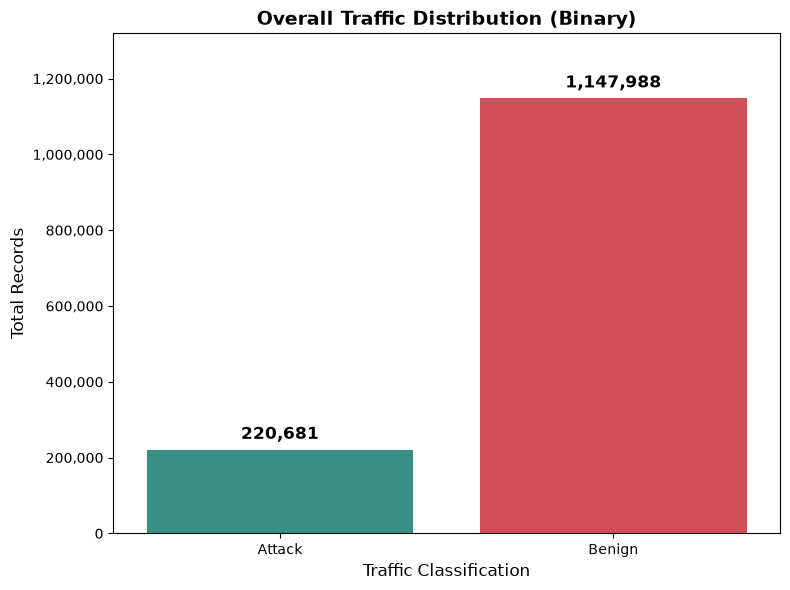

In [57]:
binary_counts = (
    y_train_t.value_counts().to_pandas()
)
binary_counts['Target'] = binary_counts['Target'].map({
    0: 'Benign',
    1: 'Attack'
})
plt.figure(figsize=(8, 6))


ax = sns.barplot(
    data=binary_counts, 
    x="Target", 
    y="count", 
    palette=["#2a9d8f", "#e63946"]
)


plt.title("Overall Traffic Distribution (Binary)", fontsize=14, fontweight='bold')
plt.xlabel("Traffic Classification", fontsize=12)
plt.ylabel("Total Records", fontsize=12)


ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))


for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', 
                fontsize=12, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')


plt.ylim(0, binary_counts["count"].max() * 1.15)

plt.tight_layout()
plt.show()

It's clear that the data is highly unbalanced 

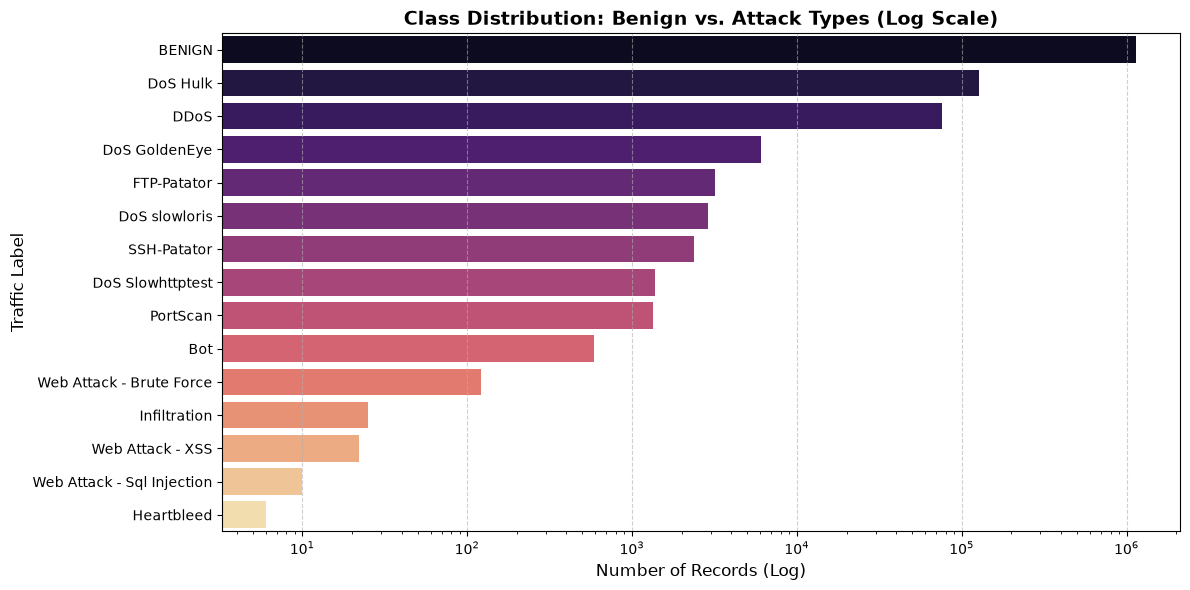

In [61]:
# label_counts = (
#     X_train.group_by("Label")
#     .len(name="Count")
#     .sort("Count", descending=True)
#     .to_pandas()
# )
label_counts = (
    y_train.value_counts().sort('count', descending=True).to_pandas()
)

plt.figure(figsize=(12, 6))
sns.barplot(data=label_counts, y="Label", x="count", palette="magma")


plt.xscale("log")
plt.title("Class Distribution: Benign vs. Attack Types (Log Scale)", fontsize=14, fontweight='bold')
plt.xlabel("Number of Records (Log)", fontsize=12)
plt.ylabel("Traffic Label", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [62]:
y_train.value_counts()

Label,count
str,u32
"""DoS Slowhttptest""",1385
"""DoS GoldenEye""",6049
"""FTP-Patator""",3175
"""Web Attack - Sql Injection""",10
"""DDoS""",76078
"""Bot""",590
"""PortScan""",1336
"""Infiltration""",25
"""Heartbleed""",6


## 4.4 Mutual Information

In [63]:
X_sample = X_train.sample(n=100000, seed=42).to_pandas()
y_sample = y_train.sample(n=100000, seed=42).to_pandas()


print("Calculating Mutual Information ...")
mi_scores = mutual_info_classif(X_sample, y_sample, random_state=42)


mi_series = pd.Series(mi_scores, index=X_sample.columns).sort_values(ascending=False)

print("\nTop 10 Features by Mutual Information:")
print(mi_series.head(10))

Calculating Mutual Information ...

Top 10 Features by Mutual Information:
Packet Length Variance        0.568596
Bwd Packet Length Max         0.537814
Bwd Init Win Bytes            0.529433
Fwd Packet Length Std         0.505054
Bwd Packet Length Mean        0.501817
Fwd Packet Length Max         0.498831
Total Length of Fwd Packet    0.470446
Fwd Packet Length Mean        0.422651
Flow Duration                 0.392579
Flow IAT Max                  0.384260
dtype: float64


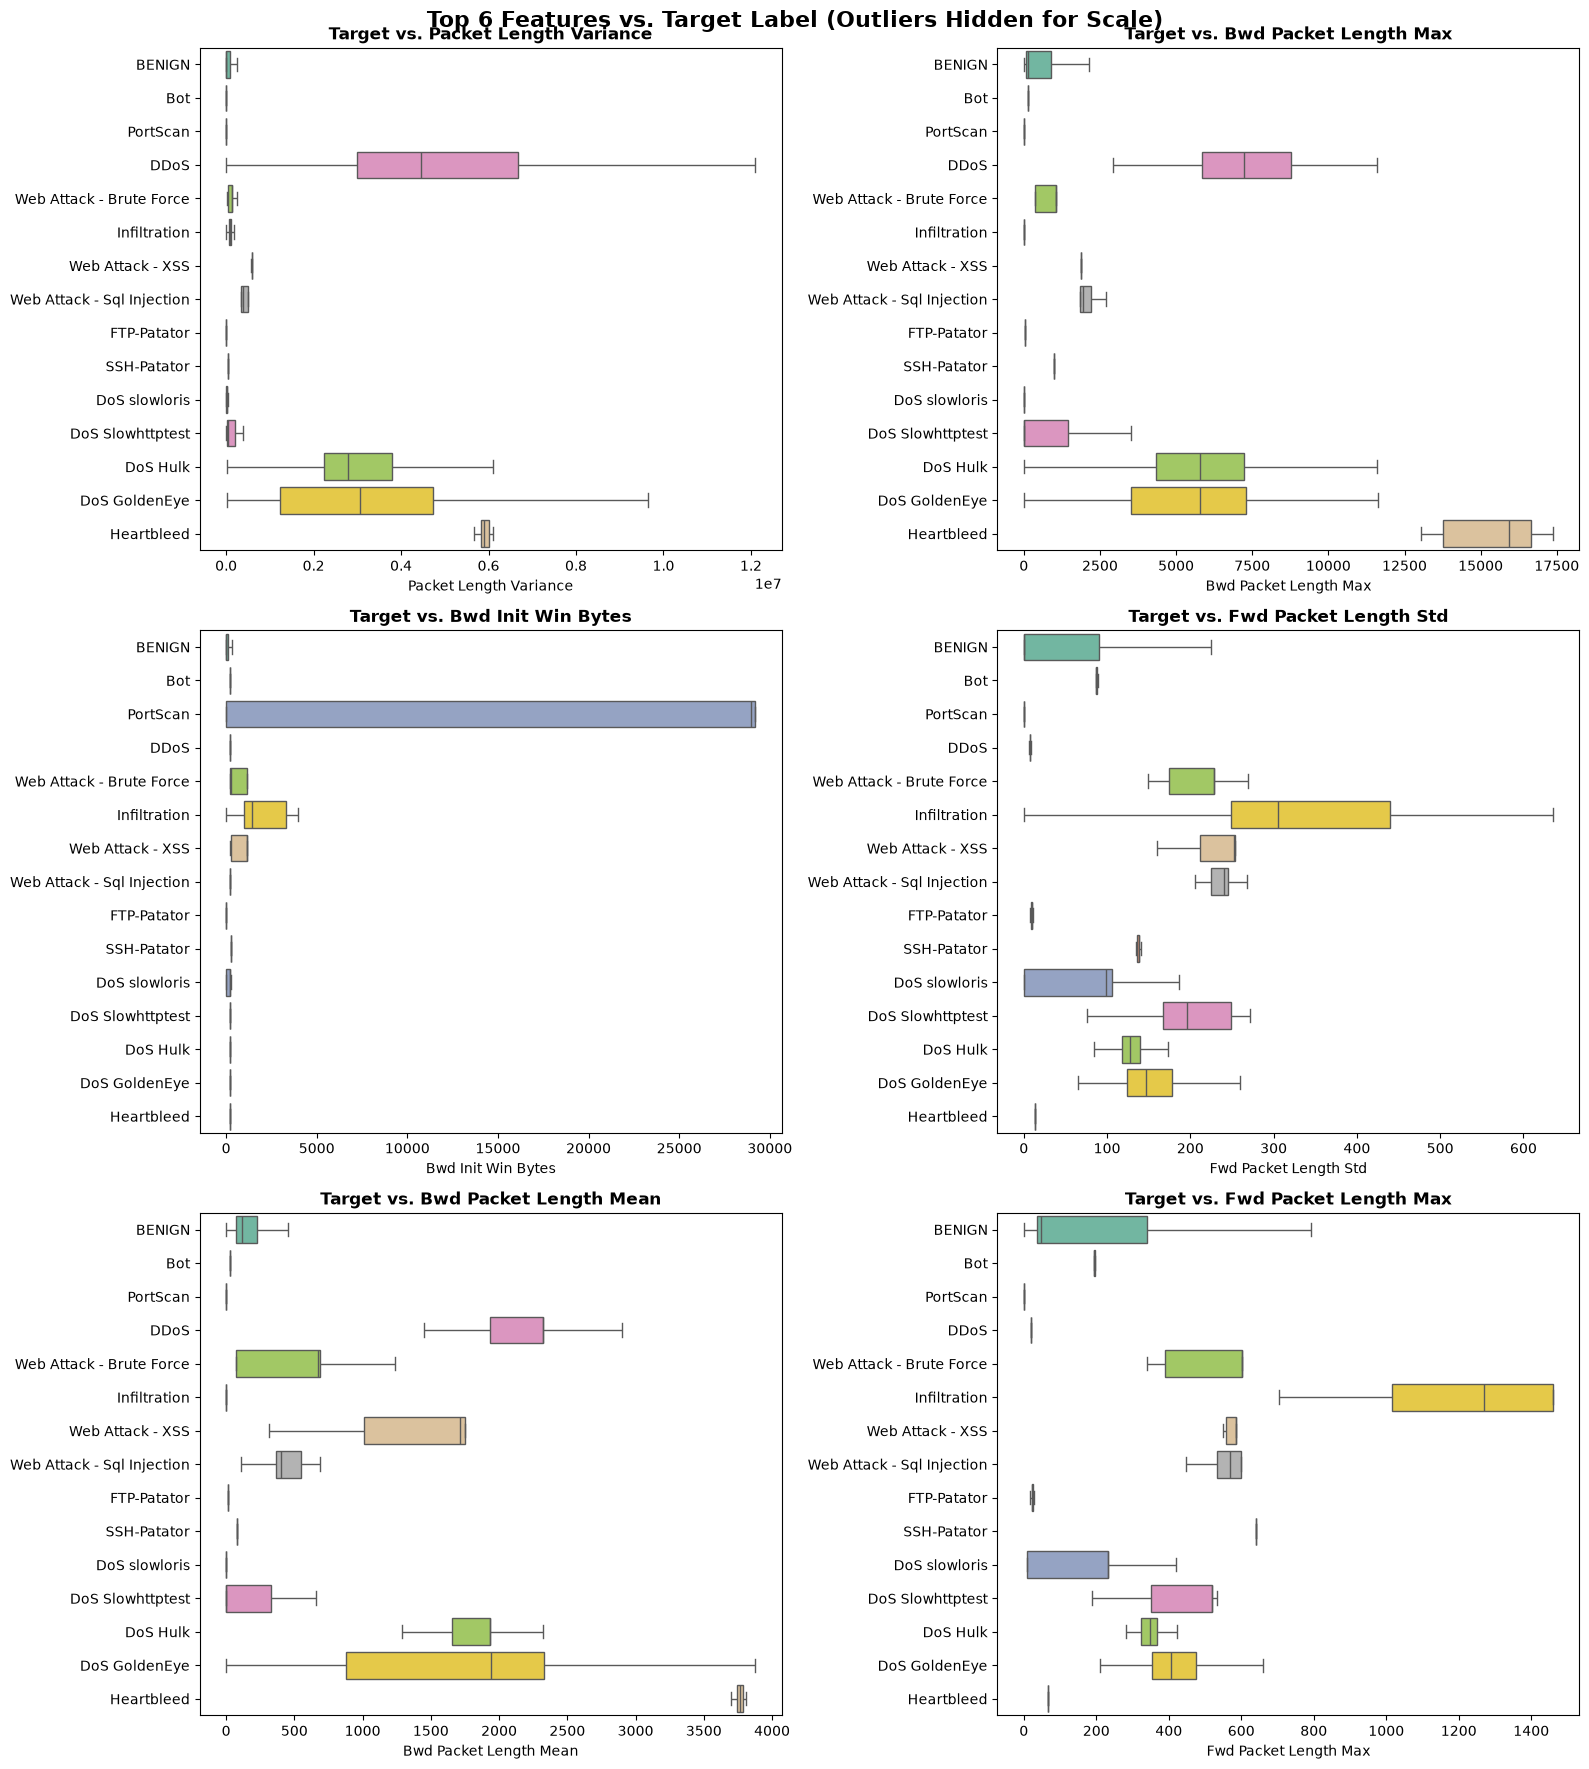

In [64]:
top_6_features = mi_series.head(6).index.tolist()


plot_cols = top_6_features + ["Label"]
plot_df = data_reduced.select(plot_cols).to_pandas()


fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for i, feature in enumerate(top_6_features):
    ax = axes[i]
    

    sns.boxplot(
        data=plot_df, 
        y="Label", 
        x=feature, 
        ax=ax, 
        palette="Set2",
        showfliers=False 
    )
    
    ax.set_title(f"Target vs. {feature}", fontweight='bold')
    ax.set_xlabel(feature)
    ax.set_ylabel("")

plt.suptitle("Top 6 Features vs. Target Label (Outliers Hidden for Scale)", 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Preprocessing

## 5.1 Identifier Coulmns Remover

In [43]:
class IdentifierColumnsRemover(TransformerMixin, BaseEstimator):
    def __init__(self, features_to_drop: list[str]) -> None:
        self.features_to_drop_ = features_to_drop

    def fit(self, X: pl.DataFrame, y= None):
        self.n_features_in_ = X.shape[1]
        self.features_names_in = X.columns
        return self
    
    def transform(self, X: pl.DataFrame)-> pl.DataFrame:
        check_is_fitted(self)
        return X.drop(self.features_to_drop_)

## 5.2 Low Non-Zero Features Remover

In [44]:
class LowNonZeroFeatureRemover(TransformerMixin, BaseEstimator):
    def __init__(self, threshold) -> None:
        self.threshold = threshold

    def fit(self, X: pl.DataFrame, y=None):
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = X.columns
        numeric_cols = X.select(cs.numeric()).columns

        self.features_to_drop_ = [
            col for col in numeric_cols
            if (X[col] != 0).sum() <= self.threshold
        ]

        return self
    
    def transform(self, X)-> pl.DataFrame:
        check_is_fitted(self, 'features_to_drop_')
        return X.drop(self.features_to_drop_)

## 5.3 Duplicates Remover

In [45]:
class DuplicatesRemover(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        self.features_names_in = X.columns
        return self
    
    def transform(self, X)-> pl.DataFrame:
        return X.unique(keep='first', maintain_order=True)

## 5.4 Missing and Infinite Values Remover

In [46]:
class NullRemover(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        self.features_names_in = X.columns
        return self
    
    def transform(self, X)-> pl.DataFrame:
        check_is_fitted(self)
        X = X.with_columns(
            pl.when(cs.numeric().is_infinite())
            .then(None)
            .otherwise(cs.numeric())
            .name.keep()
        )
        X = X.with_columns(
            cs.numeric().fill_nan(None).name.keep()
        )
        return X.drop_nulls()

## 5.5 Impossible Negatives Remover

In [47]:
class ImpossibleNegativesRemover(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.n_features_n_ = X.shape[1]
        self.features_names_in = X.columns
        return self
    
    def transform(self, X)-> pl.DataFrame:
        check_is_fitted(self)
        return X.filter(~pl.any_horizontal(cs.numeric() < 0))


## 5.6 Feature Selector (using correlation analysis)

In [68]:
class GreedyCorrelationSelector(TransformerMixin, BaseEstimator):
    def __init__(self, threshold) -> None:
        self.threshold = threshold

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        self.features_names_in = X.columns
        numeric_cols = X.select(cs.numeric()).columns
        numeric_df = X.select(numeric_cols)


        corr_matrix_pl = numeric_df.corr()


        corr_matrix = corr_matrix_pl.to_pandas()
        corr_matrix.index = numeric_cols  

        self.features_to_drop_ = set()


        for i in range(len(corr_matrix.columns)):
            for j in range(i + 1, len(corr_matrix.columns)):
                col_A = corr_matrix.columns[i]
                col_B = corr_matrix.columns[j]
        
        
                if abs(corr_matrix.iloc[i, j]) > self.threshold:
            
                    if col_A not in self.features_to_drop_:
                        self.features_to_drop_.add(col_B)
        return self
    
    def transform(self, X)-> pl.DataFrame:
        check_is_fitted(self, 'features_to_drop_')
        return X.drop(self.features_to_drop_)


## 5.7 Target Relabeler

In [69]:
class RelabelTarget(TransformerMixin, BaseEstimator):
    def __init__(self, make_binary: bool) -> None:
        self.make_binary_ = make_binary
    def fit(self, X, y=None):
        self.n_features_n_ = X.shape[1]
        self.features_names_in = X.columns
        return self
    def transform(self, X)-> pl.DataFrame:
        X = X.with_columns(
            pl.when(pl.col("Label").str.ends_with("Attempted"))
            .then(pl.lit("BENIGN"))
            .otherwise(pl.col("Label"))
            .alias("Label")
        )
        if self.make_binary_:
            X = X.with_columns(
            pl.when(pl.col("Label") == "BENIGN")
            .then(0)
            .otherwise(1)
            .name.keep()
            )
        return X


## 5.8 Dataset Cleaner

In [ ]:
def clean_dataset(
        df: pl.DataFrame, identifier_features_to_drop: list[str] = ['Flow ID','Src IP','Src Port','Dst IP','Dst Port','Timestamp'],
        make_target_binary: bool = False,
        attack_only: bool = False):
    
    cleaners = [
    IdentifierColumnsRemover(identifier_features_to_drop),
    NullRemover(),
    ImpossibleNegativesRemover(),
    RelabelTarget(make_target_binary),
    DuplicatesRemover()
    ]
    
    for cleaner in cleaners:
        df = cleaner.fit_transform(df)
    if attack_only:
        df = df.filter(pl.col("Label") != "BENIGN")
    return df

## 5.9 One Hot Encoder

In [93]:
preprocessor = ColumnTransformer(
        transformers=[
            (
                "protocol",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                ["Protocol"],
            ),
        ],
        remainder="passthrough",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

# 6. Baseline Models

## 6.1 Binary classification (BENIGN & Attack only)

### 6.1.1 Random Forest

In [78]:
def make_model(model, low_non_zero_threshold = 200, correlation_threshold = 0.95):
    
    return make_pipeline(
        LowNonZeroFeatureRemover(low_non_zero_threshold),
        GreedyCorrelationSelector(correlation_threshold),
        preprocessor,
        model
    )

In [80]:
def evaluate_model(
    model,
    X_train,
    y_train,
    X_test,
    y_test,
    n_splits=5,
    random_state=42,
    positive_label=1,
    cv_n_jobs=1,
):

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    scoring = {
        "f1_macro": "f1_macro",
        "f1_weighted": "f1_weighted",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "accuracy": "accuracy",
    }

    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=cv_n_jobs,
        return_train_score=False,
        error_score="raise",
    )

    print(f"--- {n_splits}-Fold Cross-Validation ---")

    cv_summary = {}

    for metric in scoring:
        scores = cv_results[f"test_{metric}"]
        mean_score = float(np.mean(scores))
        std_score = float(np.std(scores))

        cv_summary[metric] = {
            "scores": scores,
            "mean": mean_score,
            "std": std_score,
        }

        print(
            f"{metric}: {mean_score:.4f} "
            f"+/- {std_score:.4f}"
        )


    model.fit(X_train, y_train)


    y_pred = model.predict(X_test)

    print("\n--- Test Classification Report ---")
    report = classification_report(
        y_test,
        y_pred,
        zero_division=0,
    )
    print(report)

    test_f1_macro = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0,
    )

    test_f1_weighted = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0,
    )

    print(f"Test Macro F1:    {test_f1_macro:.4f}")
    print(f"Test Weighted F1: {test_f1_weighted:.4f}")


    test_labels = np.unique(np.asarray(y_test).ravel())
    test_f1_attack = None

    if len(test_labels) == 2 and positive_label in test_labels:
        test_f1_attack = f1_score(
            y_test,
            y_pred,
            pos_label=positive_label,
            zero_division=0,
        )

        print(
            f"Test Attack F1 "
            f"(positive label={positive_label}): "
            f"{test_f1_attack:.4f}"
        )

    return {
        "model": model,
        "cv_results": cv_summary,
        "y_pred": y_pred,
        "classification_report": report,
        "test_f1_macro": test_f1_macro,
        "test_f1_weighted": test_f1_weighted,
        "test_f1_attack": test_f1_attack,
    }

In [114]:
df_clean = clean_dataset(df,make_target_binary=True)

In [115]:
X = df_clean.drop('Label')
y = df_clean['Label']

In [116]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42, stratify=y)

In [82]:
forest_clf = make_model(
    RandomForestClassifier(n_estimators=100,class_weight='balanced',random_state=42,n_jobs=-1),
    )

In [83]:
results = evaluate_model(
    forest_clf,
    X_train,
    y_train,
    X_test,
    y_test
)

--- 5-Fold Cross-Validation ---
f1_macro: 0.9997 +/- 0.0000
f1_weighted: 0.9998 +/- 0.0000
precision_macro: 0.9997 +/- 0.0000
recall_macro: 0.9997 +/- 0.0000
accuracy: 0.9998 +/- 0.0000

--- Test Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    286998
           1       1.00      1.00      1.00     55170

    accuracy                           1.00    342168
   macro avg       1.00      1.00      1.00    342168
weighted avg       1.00      1.00      1.00    342168

Test Macro F1:    0.9997
Test Weighted F1: 0.9998
Test Attack F1 (positive label=1): 0.9995


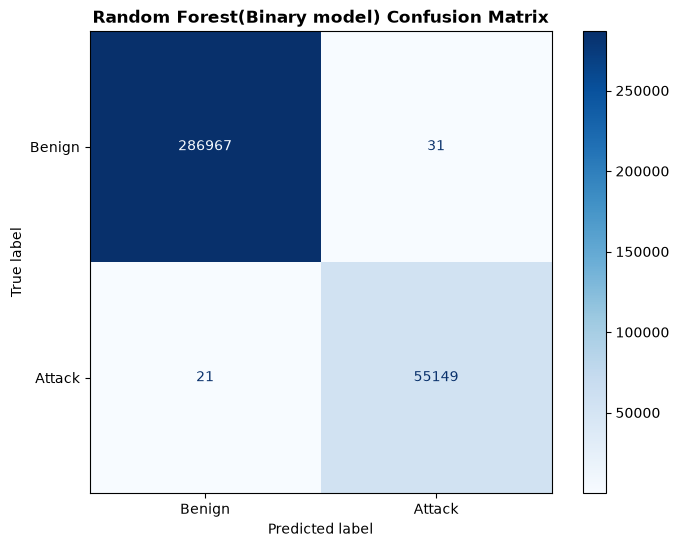

In [86]:
cm = confusion_matrix(y_test, results['y_pred'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", "Attack"])

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Random Forest(Binary model) Confusion Matrix", fontweight="bold")
plt.show()

### 6.1.2 XGBOOST

In [103]:
print("XGBoost version:", xgb.__version__)
print("CUDA enabled:", xgb.build_info().get("USE_CUDA"))

XGBoost version: 3.4.1
CUDA enabled: True


In [ ]:
xgb_model = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",

    tree_method="hist",
    device="cuda",


    n_estimators=600,
    learning_rate=0.05,


    max_depth=5,
    min_child_weight=3,
    gamma=0,


    subsample=0.8,
    colsample_bytree=0.8,


    reg_alpha=0.1,
    reg_lambda=5.0,


    max_bin=128,
    random_state=42,
    n_jobs=-1,
)

In [108]:
results_xgb = evaluate_model(
    xgb_model,
    X_train,
    y_train,
    X_test,
    y_test,
)

--- 5-Fold Cross-Validation ---
f1_macro: 0.9998 +/- 0.0000
f1_weighted: 0.9999 +/- 0.0000
precision_macro: 0.9998 +/- 0.0000
recall_macro: 0.9998 +/- 0.0000
accuracy: 0.9999 +/- 0.0000

--- Test Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    286998
           1       1.00      1.00      1.00     55170

    accuracy                           1.00    342168
   macro avg       1.00      1.00      1.00    342168
weighted avg       1.00      1.00      1.00    342168

Test Macro F1:    0.9998
Test Weighted F1: 0.9999
Test Attack F1 (positive label=1): 0.9996


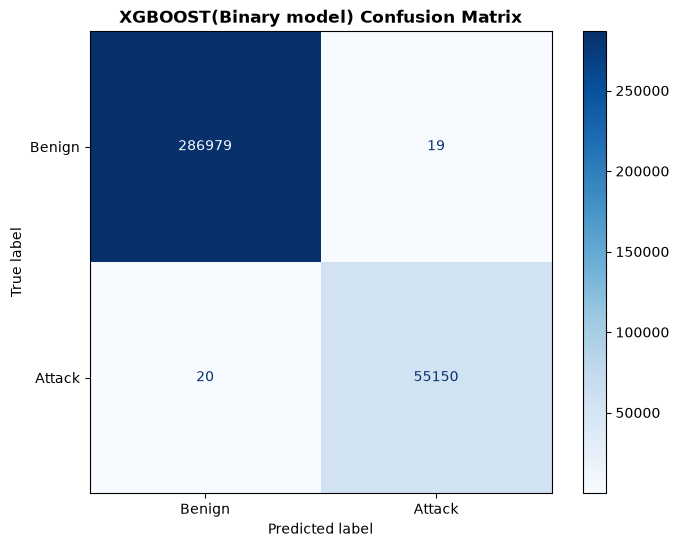

In [117]:
cm = confusion_matrix(y_test, results_xgb['y_pred'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", "Attack"])

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("XGBOOST(Binary model) Confusion Matrix", fontweight="bold")
plt.show()

## 6.2 Standard Multiclass

### 6.2.1 Random Forest

In [87]:
def plot_multiclass_matrix(y_true, y_pred, labels_in_data, display_names, title):
    
    cm = confusion_matrix(y_true, y_pred, labels=labels_in_data)
    
    
    fig, ax = plt.subplots(figsize=(14, 12))
    
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_names)
    
    
    disp.plot(cmap="Blues", ax=ax, values_format="d", xticks_rotation="vertical")
    
    plt.title(title, fontweight="bold", fontsize=16)
    
    
    plt.tight_layout()
    plt.show()

In [118]:
df_clean_multi = clean_dataset(df, make_target_binary=False)
X = df_clean_multi.drop('Label')
y = df_clean_multi['Label']
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [91]:
results_multi = evaluate_model(
    forest_clf,
    X_train,
    y_train,
    X_test,
    y_test
)

--- 5-Fold Cross-Validation ---
f1_macro: 0.9462 +/- 0.0316
f1_weighted: 0.9999 +/- 0.0000
precision_macro: 0.9716 +/- 0.0339
recall_macro: 0.9368 +/- 0.0288
accuracy: 0.9999 +/- 0.0000

--- Test Classification Report ---
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    359180
                       Bot       0.99      0.99      0.99       184
                      DDoS       1.00      1.00      1.00     23547
             DoS GoldenEye       1.00      1.00      1.00      1762
                  DoS Hulk       1.00      1.00      1.00     39560
          DoS Slowhttptest       0.99      1.00      0.99       421
             DoS slowloris       1.00      1.00      1.00       847
               FTP-Patator       1.00      1.00      1.00       967
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      0.86      0.92         7
                  PortScan   

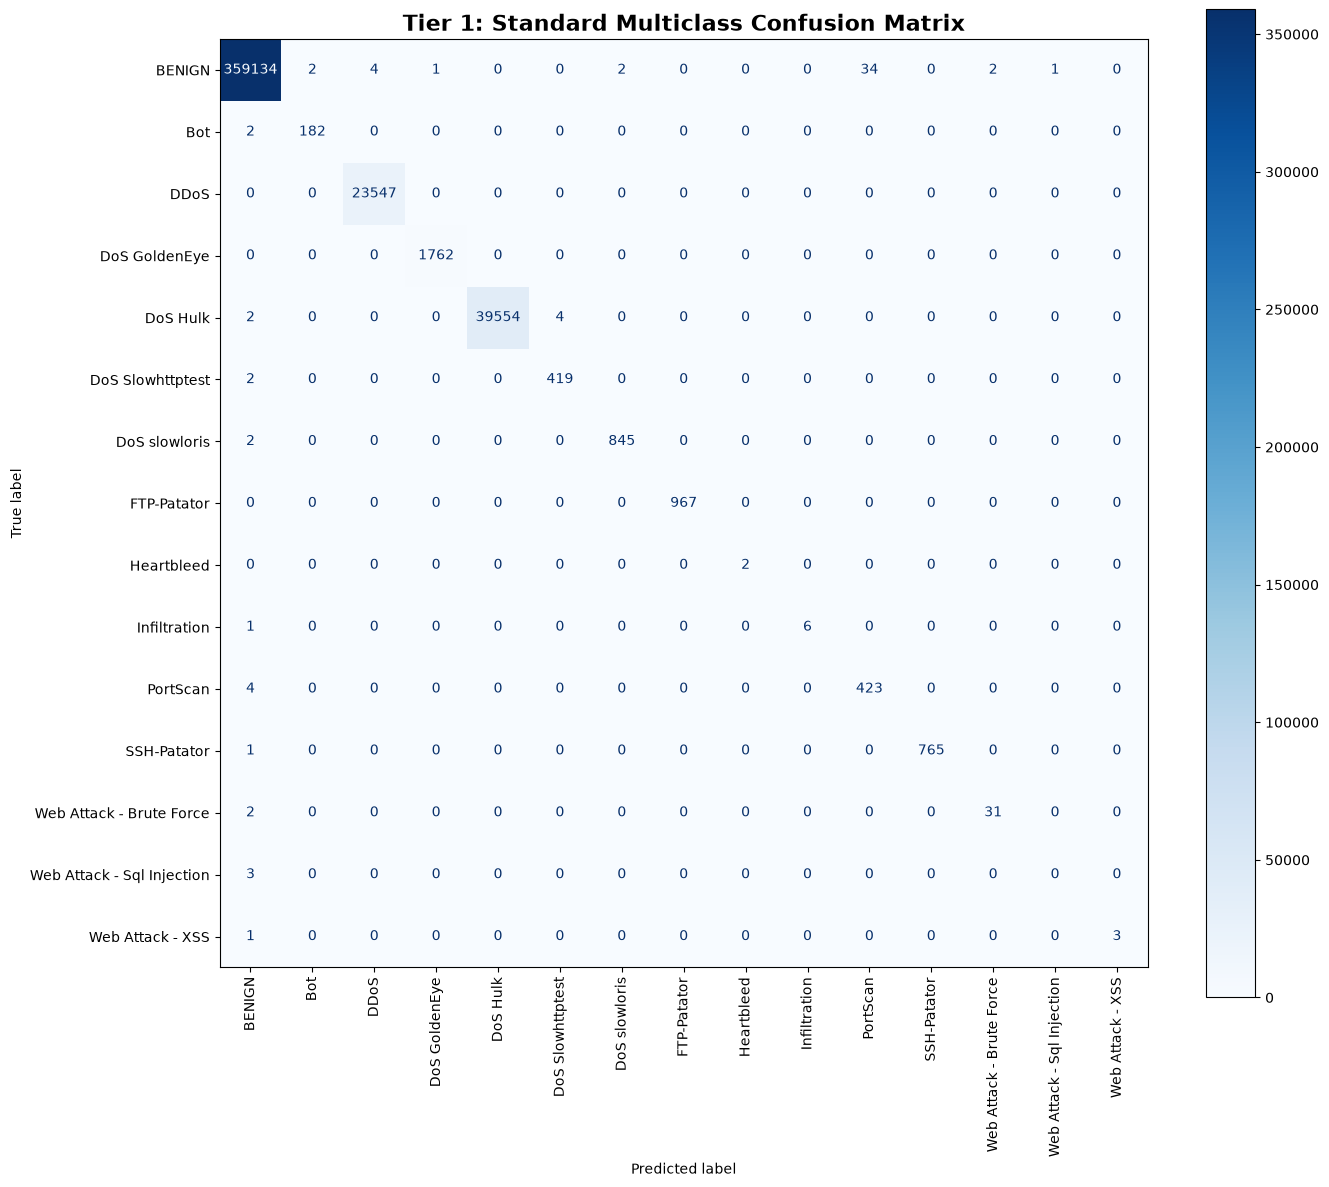

In [ ]:
plot_multiclass_matrix(
    y_test, 
    results_multi['y_pred'], 
    labels_in_data=forest_clf.classes_, 
    display_names=forest_clf.classes_,
    title="Tier 1: Standard Multiclass Confusion Matrix(Random Forest)"
)

### 6.2.2 XGBOOST

In [127]:
df_clean_multi_xgb = clean_dataset(df, make_target_binary=False)
X = df_clean_multi_xgb.drop('Label')
y = df_clean_multi_xgb['Label']
encoder = LabelEncoder()
y = encoder.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [128]:
xgb_model_multi = xgb.XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    tree_method="hist",
    device="cuda",
    n_estimators=600,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5.0,
    max_bin=128,
    random_state=42,
    n_jobs=-1,
)

In [129]:
results_xgb_multi = evaluate_model(
    xgb_model_multi,
    X_train,
    y_train,
    X_test,
    y_test,
)

--- 5-Fold Cross-Validation ---
f1_macro: 0.9357 +/- 0.0384
f1_weighted: 0.9998 +/- 0.0000
precision_macro: 0.9641 +/- 0.0395
recall_macro: 0.9181 +/- 0.0376
accuracy: 0.9998 +/- 0.0000

--- Test Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    358924
           1       1.00      1.00      1.00       170
           2       1.00      1.00      1.00     23746
           3       1.00      1.00      1.00      1864
           4       1.00      1.00      1.00     39563
           5       1.00      1.00      1.00       426
           6       1.00      1.00      1.00       871
           7       1.00      1.00      1.00       951
           8       1.00      0.50      0.67         2
           9       1.00      0.88      0.93         8
          10       0.93      0.94      0.93       406
          11       1.00      1.00      1.00       728
          12       0.97      0.89      0.93        36
          13       1.

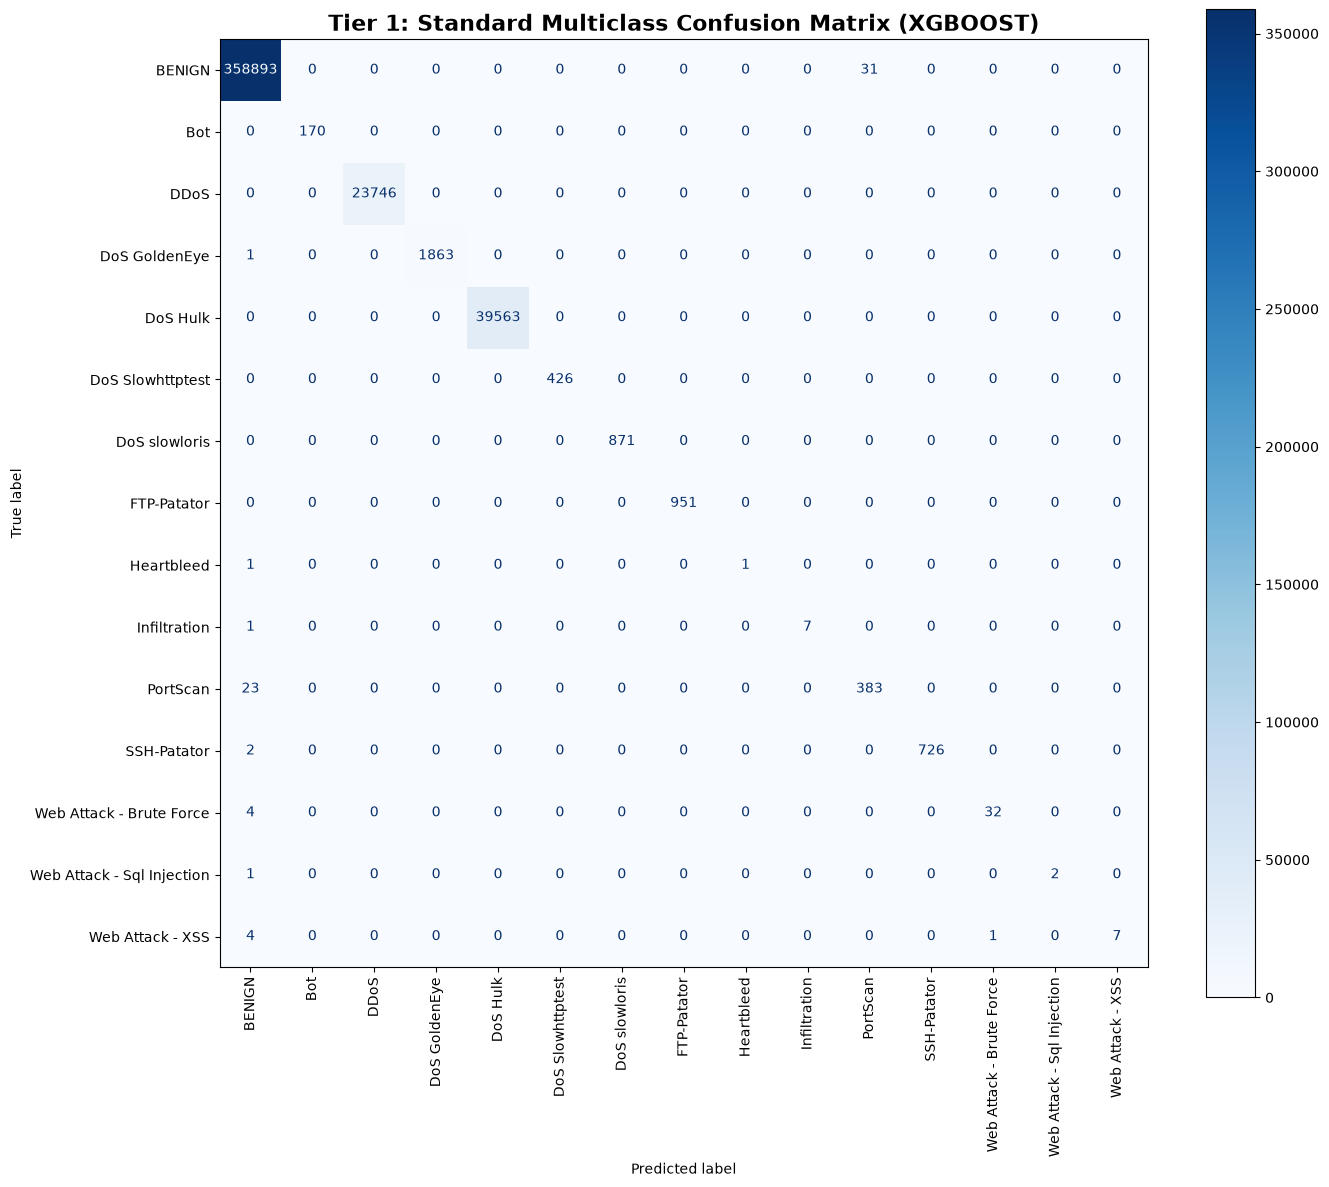

In [137]:
plot_multiclass_matrix(
    encoder.inverse_transform(y_test), 
    encoder.inverse_transform(results_xgb_multi['y_pred']), 
    labels_in_data=encoder.inverse_transform(xgb_model_multi.classes_), 
    display_names=encoder.inverse_transform(xgb_model_multi.classes_),
    title="Tier 1: Standard Multiclass Confusion Matrix (XGBOOST)"
)

# 6.3 Specialist Model

### 6.3.1 Random Forest

In [99]:
df_clean_specialist = clean_dataset(df,make_target_binary=False, attack_only=True)
X = df_clean_specialist.drop('Label')
y = df_clean_specialist['Label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [100]:
results_specialist = evaluate_model(
    forest_clf,
    X_train,
    y_train,
    X_test,
    y_test
)

--- 5-Fold Cross-Validation ---
f1_macro: 0.9567 +/- 0.0121
f1_weighted: 0.9998 +/- 0.0001
precision_macro: 0.9725 +/- 0.0095
recall_macro: 0.9511 +/- 0.0232
accuracy: 0.9998 +/- 0.0001

--- Test Classification Report ---
                            precision    recall  f1-score   support

                       Bot       1.00      1.00      1.00       148
                      DDoS       1.00      1.00      1.00     19020
             DoS GoldenEye       1.00      1.00      1.00      1513
                  DoS Hulk       1.00      1.00      1.00     31657
          DoS Slowhttptest       0.99      0.99      0.99       346
             DoS slowloris       1.00      1.00      1.00       719
               FTP-Patator       1.00      1.00      1.00       794
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       1.00      1.00      1.00         6
                  PortScan       1.00      0.99      1.00       334
               SSH-Patator   

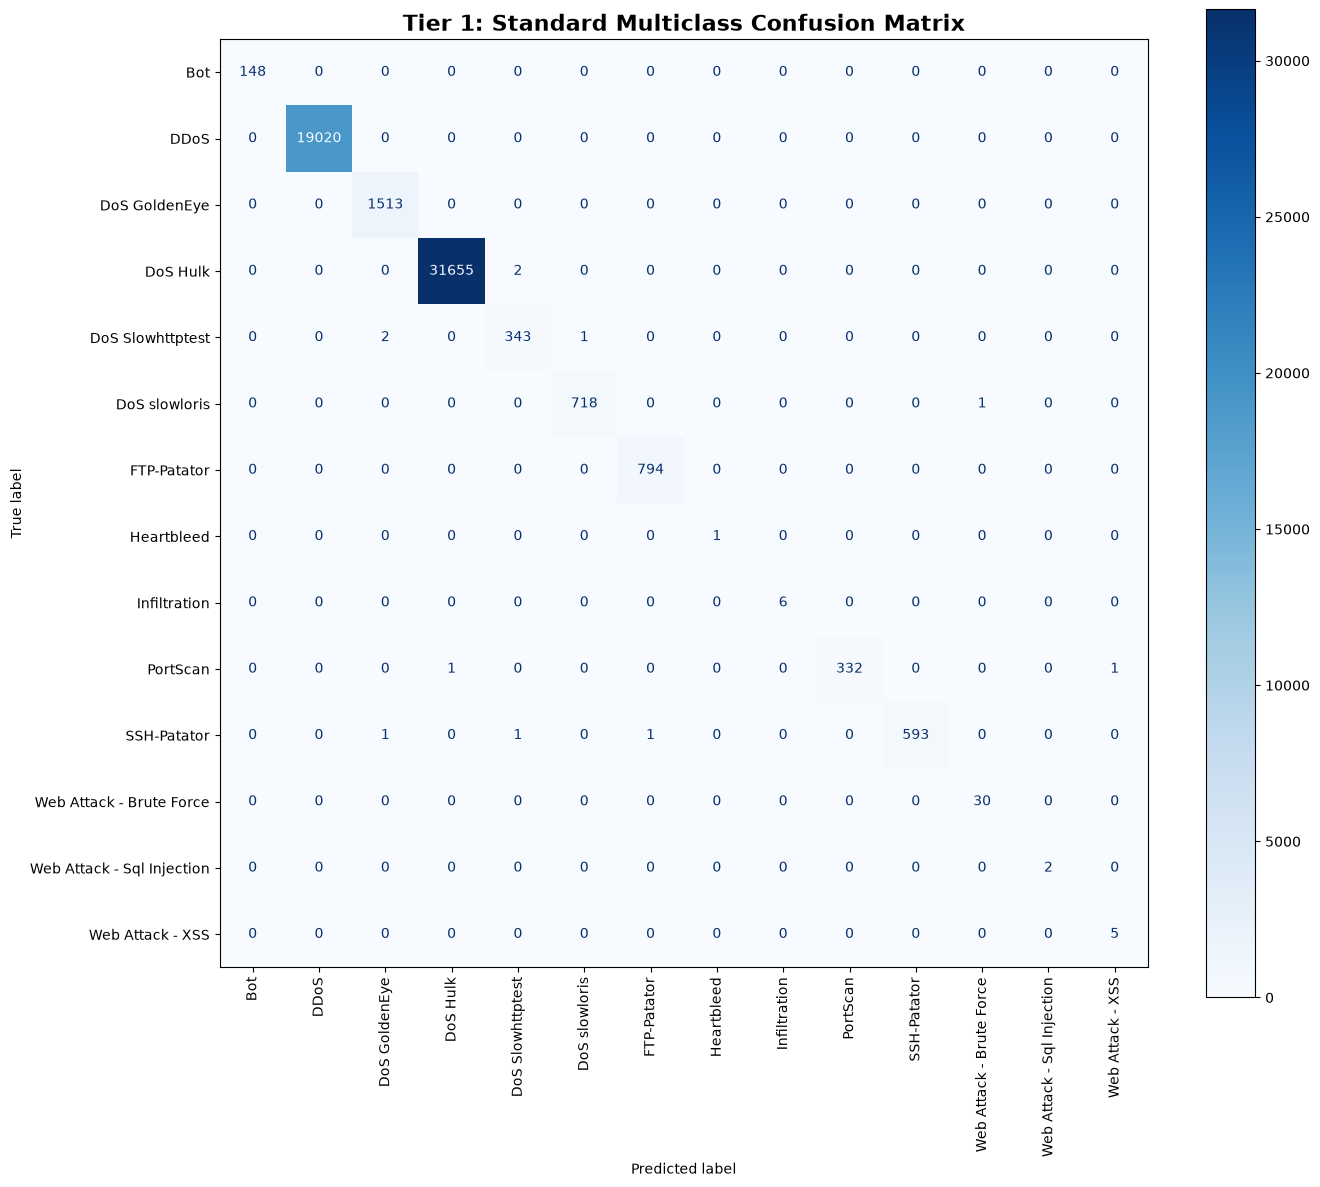

In [101]:
plot_multiclass_matrix(
    y_test, 
    results_specialist['y_pred'], 
    labels_in_data=forest_clf.classes_, 
    display_names=forest_clf.classes_,
    title="Tier 1: Standard Multiclass Confusion Matrix"
)

### 6.3.2 XGBOOST

In [138]:
df_clean_specialist_xgb = clean_dataset(df,make_target_binary=False, attack_only=True)
X = df_clean_specialist_xgb.drop('Label')
y = df_clean_specialist_xgb['Label']
encoder = LabelEncoder()
y = encoder.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [139]:
results_xgb_specialist = evaluate_model(
    xgb_model,
    X_train,
    y_train,
    X_test,
    y_test,
)

--- 5-Fold Cross-Validation ---
f1_macro: 0.9399 +/- 0.0414
f1_weighted: 0.9998 +/- 0.0000
precision_macro: 0.9524 +/- 0.0386
recall_macro: 0.9366 +/- 0.0411
accuracy: 0.9998 +/- 0.0000

--- Test Classification Report ---
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       148
           1       1.00      1.00      1.00     19020
           2       1.00      1.00      1.00      1513
           3       1.00      1.00      1.00     31657
           4       1.00      0.99      1.00       346
           5       1.00      1.00      1.00       719
           6       1.00      1.00      1.00       794
           7       1.00      1.00      1.00         1
           8       1.00      1.00      1.00         6
           9       1.00      0.99      1.00       334
          10       1.00      1.00      1.00       596
          11       0.91      0.97      0.94        30
          12       1.00      0.50      0.67         2
          13       0.

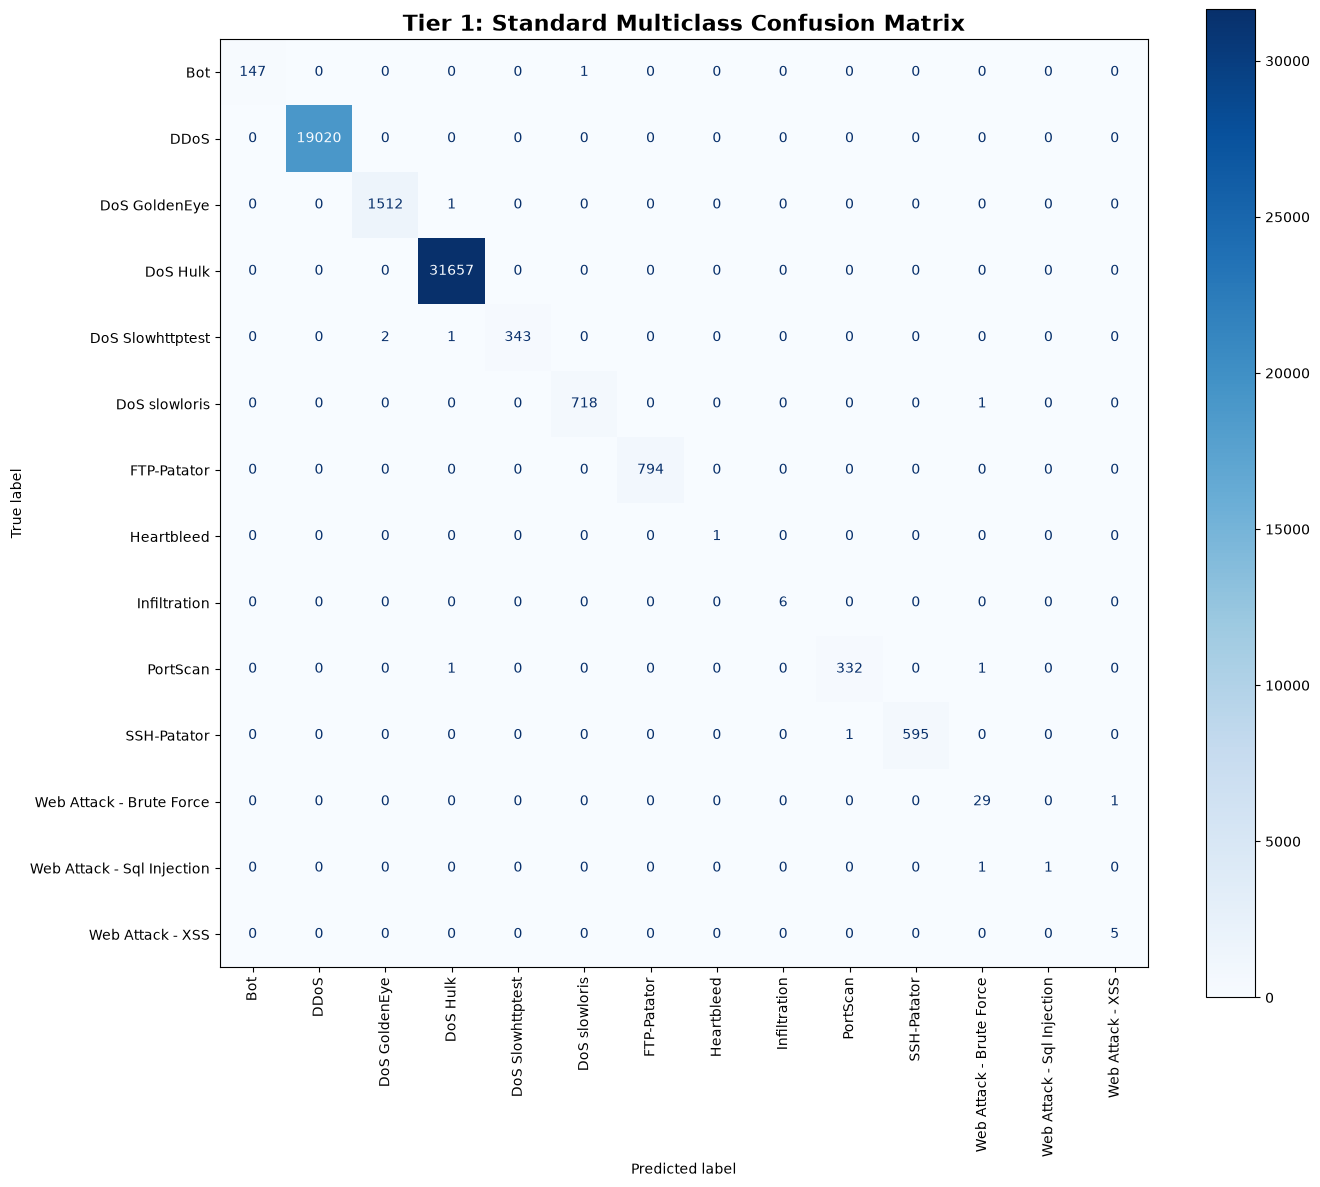

In [141]:
plot_multiclass_matrix(
    encoder.inverse_transform(y_test), 
    encoder.inverse_transform(results_xgb_specialist['y_pred']), 
    labels_in_data=encoder.inverse_transform(results_xgb_specialist['model'].classes_), 
    display_names=encoder.inverse_transform(results_xgb_specialist['model'].classes_),
    title="Tier 1: Standard Multiclass Confusion Matrix"
)

# 7. Saving the Models

In [145]:
joblib.dump(results_xgb['model'], '../models/xgb_binary_model.pkl')
joblib.dump(results['model'], '../models/rf_binary_model.pkl')
joblib.dump(results_multi['model'], '../models/standard_multi_model.pkl')
joblib.dump(results_specialist['model'], '../models/specialist_model.pkl')
joblib.dump(X_train.columns , '../models/feature_names.pkl')

['../models/feature_names.pkl']